# Лабораторная работа №4. Обработка и анализ реальных массивов данных

Описание набора данных: Kaggle, Credit Card Fraud Detection (https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data).

# 1. Загрузка данных и первичный осмотр

In [1]:
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("../Datasets/creditcard.csv")
PICS_PATH = Path("../Pics")
RESULTS_PATH = Path("../results")
PICS_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

random_state = 42

df = pd.read_csv(DATA_PATH)

print("Размерность выборки:", df.shape)
display(df.head())

Размерность выборки: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print("Информация о признаках:")
df.info()

print("\nПропущенные значения:", int(df.isnull().sum().sum()))
print("Повторяющиеся строки:", int(df.duplicated().sum()))
print("Повторяющиеся строки среди мошенничеств:", int(df[df["Class"] == 1].duplicated().sum()))

display(df.describe().T.round(3))

Информация о признаках:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 2

Повторяющиеся строки: 1081
Повторяющиеся строки среди мошенничеств: 19


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.860,47488.146,0.000,54201.500,84692.000,139320.500,172792.000
V1,284807.0,0.000,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.0,0.000,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.0,-0.000,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.0,0.000,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.0,0.000,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.0,0.000,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.0,-0.000,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.0,0.000,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.0,-0.000,1.099,-13.434,-0.643,-0.051,0.597,15.595


Данные не содержат пропусков. Присутствует 1081 дубликат, все они относятся к классу 0. Признаки V1-V28 уже центрированы (среднее около нуля) и являются результатом PCA-преобразования исходных анонимных признаков. Time отсчитывается в секундах от первой транзакции, Amount задаёт сумму операции.

# 2. Разведочный анализ данных

In [3]:
df = df.drop_duplicates().reset_index(drop=True)

class_counts = df["Class"].value_counts().sort_index()

print("Размерность после удаления дубликатов:", df.shape)

table = pd.DataFrame({
    "Класс": ["Легитимная (0)", "Мошенничество (1)"],
    "Число объектов": [class_counts[0], class_counts[1]],
    "Доля, %": [class_counts[0] / len(df) * 100, class_counts[1] / len(df) * 100]
})

display(table.round(3))

Размерность после удаления дубликатов: (283726, 31)


,Класс,Число объектов,"Доля, %"
0,Легитимная (0),283253,99.833
1,Мошенничество (1),473,0.167


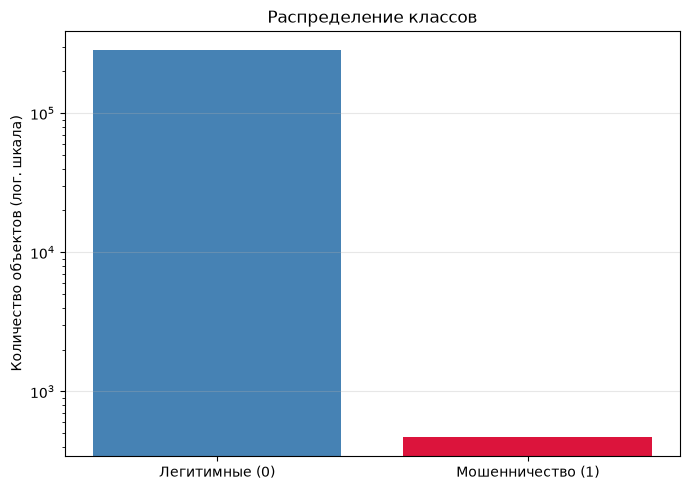

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(["Легитимные (0)", "Мошенничество (1)"], [class_counts[0], class_counts[1]], color=["steelblue", "crimson"])
ax.set_yscale("log")
ax.set_title("Распределение классов")
ax.set_ylabel("Количество объектов (лог. шкала)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(PICS_PATH / "1_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Класс 0 содержит 283253 объекта, класс 1 лишь 473. Дисбаланс составляет примерно 599 к 1, поэтому задача классификации является сильно несбалансированной. Логарифмическая шкала по оси ординат нужна, чтобы был виден малочисленный класс.

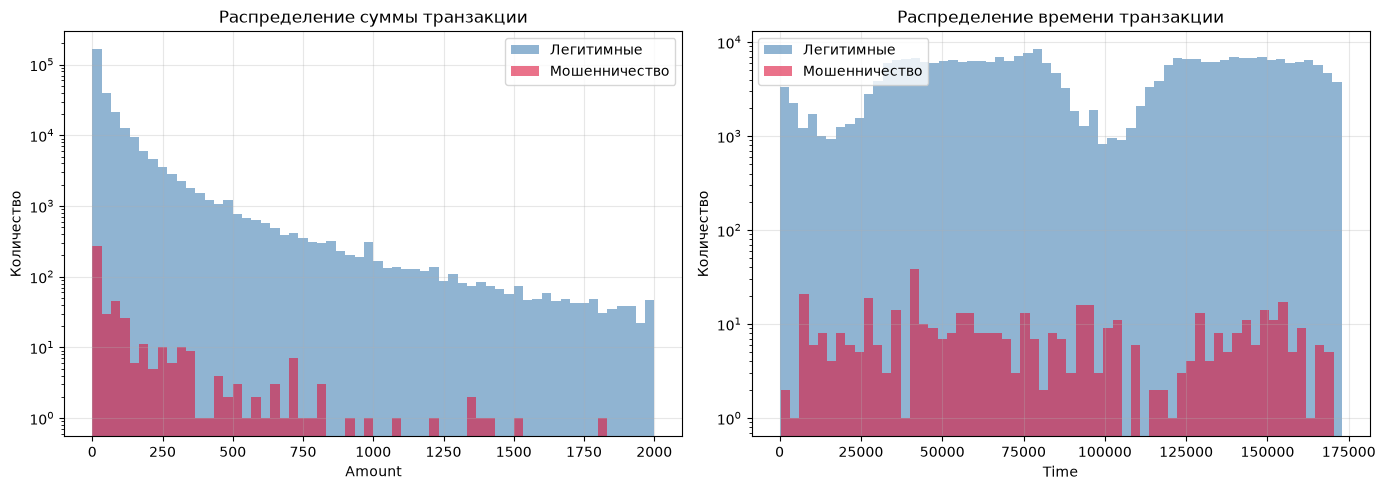

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df.loc[df["Class"] == 0, "Amount"], bins=60, range=(0, 2000), alpha=0.6, label="Легитимные", color="steelblue")
axes[0].hist(df.loc[df["Class"] == 1, "Amount"], bins=60, range=(0, 2000), alpha=0.6, label="Мошенничество", color="crimson")
axes[0].set_title("Распределение суммы транзакции")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Количество")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(df.loc[df["Class"] == 0, "Time"], bins=60, alpha=0.6, label="Легитимные", color="steelblue")
axes[1].hist(df.loc[df["Class"] == 1, "Time"], bins=60, alpha=0.6, label="Мошенничество", color="crimson")
axes[1].set_title("Распределение времени транзакции")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Количество")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(PICS_PATH / "2_amount_time.png", dpi=300, bbox_inches="tight")
plt.show()

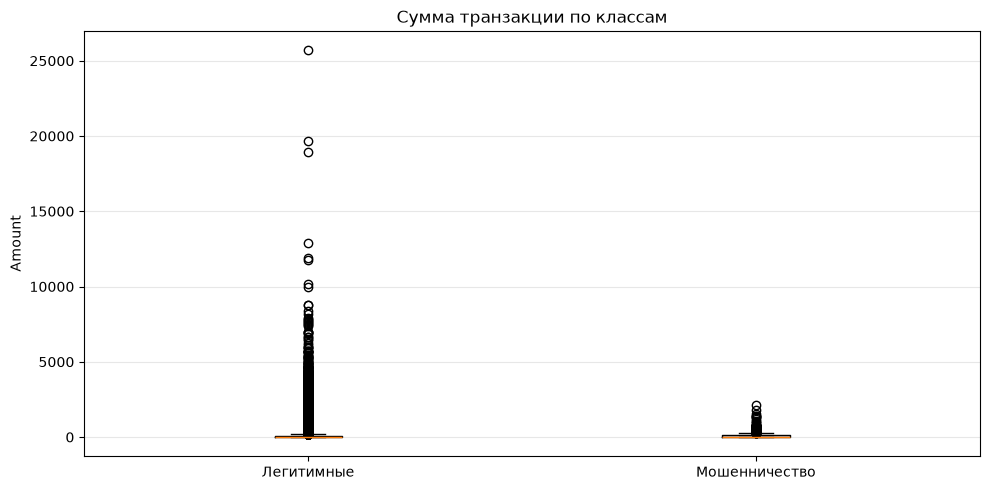

Средняя сумма мошенничества: 123.87
Средняя сумма легитимной: 88.41
Доля мошенничеств среди сумм более 1000: 0.31 %


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot(
    [df.loc[df["Class"] == 0, "Amount"], df.loc[df["Class"] == 1, "Amount"]],
    tick_labels=["Легитимные", "Мошенничество"]
)
ax.set_title("Сумма транзакции по классам")
ax.set_ylabel("Amount")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(PICS_PATH / "3_amount_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

print("Средняя сумма мошенничества:", round(df.loc[df["Class"] == 1, "Amount"].mean(), 2))
print("Средняя сумма легитимной:", round(df.loc[df["Class"] == 0, "Amount"].mean(), 2))
print("Доля мошенничеств среди сумм более 1000:", round(df.loc[df["Amount"] > 1000, "Class"].mean() * 100, 2), "%")

Большинство транзакций имеет небольшую сумму. У мошеннических операций распределение суммы шире, средняя сумма выше. Мошенничества распределены практически по всему интервалу времени, а пики легитимных операций приходятся на дневные и вечерние часы.

In [7]:
fraud_means = df.groupby("Class")[["Time", "Amount"]].mean().T

display(fraud_means.round(2))

Class,0,1
Time,94835.06,80450.51
Amount,88.41,123.87


# 3. Корреляционный анализ

In [8]:
feature_cols = [col for col in df.columns if col not in ("Class", "Time")]
corr_target = df[feature_cols + ["Class"]].corr(numeric_only=True)["Class"].drop("Class")
corr_target = corr_target.sort_values()

display(corr_target.to_frame(name="Корреляция с Class").round(3))

,Корреляция с Class
V17,-0.313
V14,-0.293
V12,-0.251
V10,-0.207
V16,-0.187
V3,-0.182
V7,-0.172
V18,-0.105
V1,-0.094
V9,-0.094


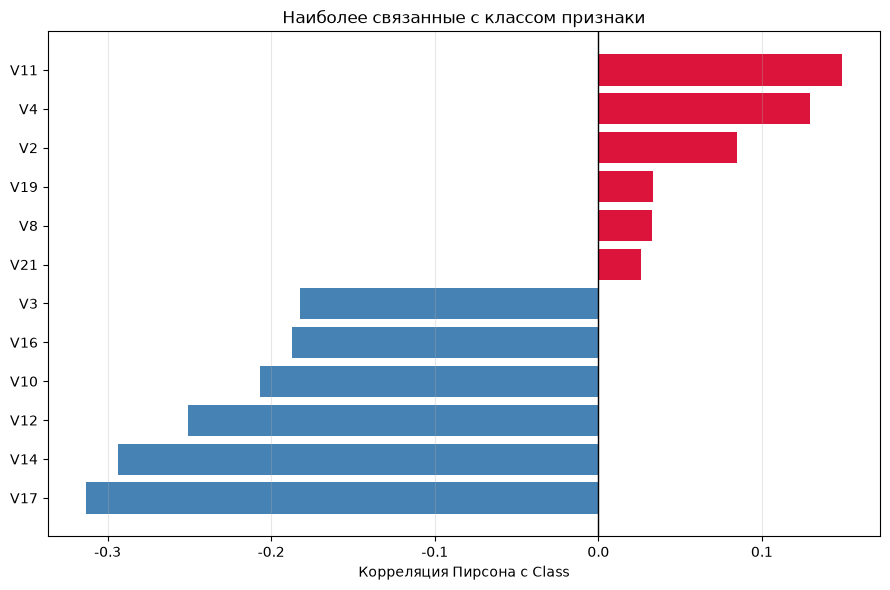

In [9]:
top_corr = pd.concat([corr_target.head(6), corr_target.tail(6)])

fig, ax = plt.subplots(figsize=(9, 6))

bar_colors = ["crimson" if value > 0 else "steelblue" for value in top_corr.values]
ax.barh(top_corr.index, top_corr.values, color=bar_colors)
ax.set_title("Наиболее связанные с классом признаки")
ax.set_xlabel("Корреляция Пирсона с Class")
ax.axvline(0, color="black", linewidth=1)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
fig.savefig(PICS_PATH / "4_target_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

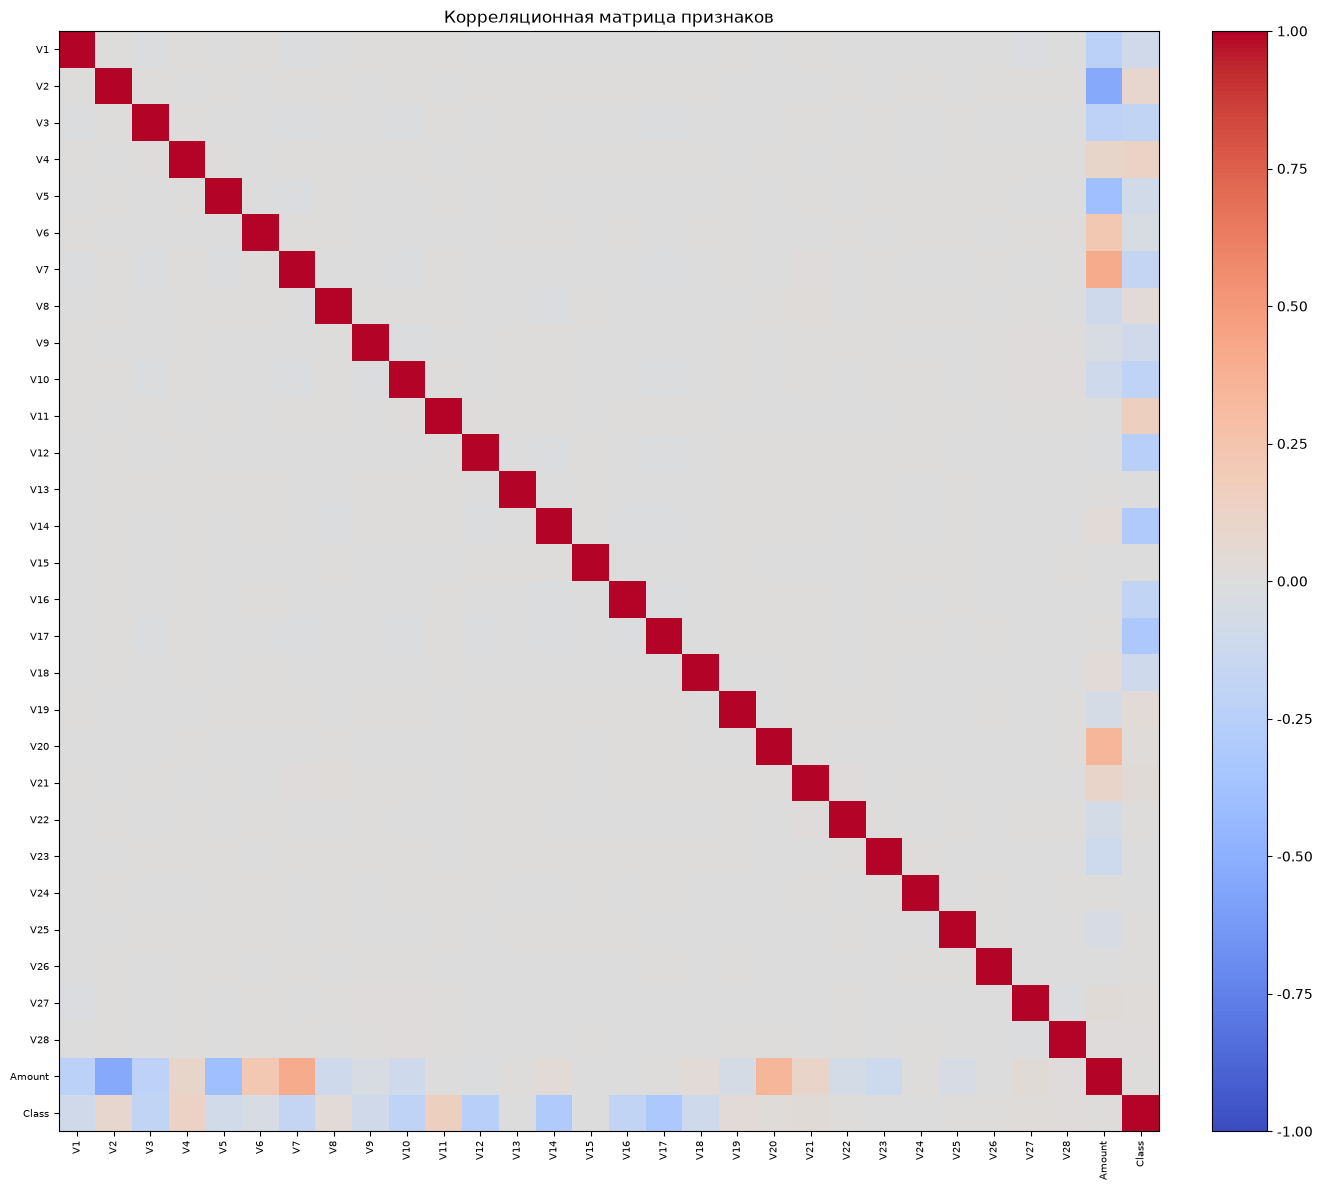

In [10]:
fig, ax = plt.subplots(figsize=(14, 12))

corr_matrix = df[feature_cols + ["Class"]].corr(numeric_only=True)
im = ax.imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr_matrix.columns, fontsize=7)
ax.set_title("Корреляционная матрица признаков")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
fig.savefig(PICS_PATH / "5_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Признаки V1-V28 не коррелируют между собой, что объясняется их происхождением из PCA. С целевой переменной сильнее всего связаны V14, V12, V10 (отрицательная связь) и V11, V4, V2 (положительная). Связь отдельного признака с классом невелика, поэтому для разделения нужны многомерные методы.

# 4. Постановка задачи и обоснование методов

Задача относится к бинарной классификации: по набору анонимных признаков транзакции определить, является ли она мошеннической. Целевая переменная Class принимает значения 0 (легитимная) и 1 (мошенничество).

Разведочный анализ показывает: данные числовые, пропусков нет, признаки V1-V28 уже нормированы, классы сильно несбалансированы (примерно 599 к 1). Задача решается методами классификации.

Для решения применяются:
- логистическая регрессия как линейная базовая модель;
- KNN как метрический метод;
- дерево решений как интерпретируемая нелинейная модель;
- случайный лес и градиентный бустинг как ансамблевые методы;
- изолирующий лес как метод поиска аномалий, который не использует метки при обучении;
- балансировка классов методами SMOTE и undersampling как этап предобработки для повышения чувствительности к малочисленному классу.

Кластеризация не применяется как основной инструмент, поскольку имеется размеченная целевая переменная. Снижение размерности (PCA, t-SNE) используется только для визуализации данных. Из-за сильного дисбаланса кроме Accuracy применяются Precision, Recall и F1-score, причём основное внимание уделяется Recall, F1 и площади под PR-кривой (average precision) по классу мошенничества.

# 5. Подготовка данных и разделение выборки

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X = df.drop(columns="Class").copy()
y = df["Class"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=random_state, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("Мошенничеств в обучающей:", int(y_train.sum()))
print("Мошенничеств в тестовой:", int(y_test.sum()))

split_table = pd.DataFrame({
    "Выборка": ["Обучение", "Тест"],
    "Всего": [len(y_train), len(y_test)],
    "Мошенничество": [int(y_train.sum()), int(y_test.sum())],
    "Доля мошенничества, %": [y_train.mean() * 100, y_test.mean() * 100]
})

display(split_table.round(3))

Обучающая выборка: (198608, 30)
Тестовая выборка: (85118, 30)
Мошенничеств в обучающей: 331
Мошенничеств в тестовой: 142


,Выборка,Всего,Мошенничество,"Доля мошенничества, %"
0,Обучение,198608,331,0.167
1,Тест,85118,142,0.167


Для ускорения обучения и подбора гиперпараметров используется стратифицированная подвыборка обучающей части объёмом 30000 объектов. Доля мошенничества в ней сохраняется, поэтому оценка на кросс-валидации остаётся представительной. Тестовая выборка используется целиком и в обучении не участвует.

In [12]:
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train, y_train,
    train_size=30000,
    random_state=random_state,
    stratify=y_train
)

print("Подвыборка для обучения:", X_train_sub.shape)
print("Мошенничеств в подвыборке:", int(y_train_sub.sum()))

Подвыборка для обучения: (30000, 30)
Мошенничеств в подвыборке: 50


# 6. Визуализация структуры данных методами PCA и t-SNE

In [13]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

vis_scaler = StandardScaler()
X_train_vis = vis_scaler.fit_transform(X_train)

pca_vis = PCA(n_components=2, random_state=random_state)
X_train_pca = pca_vis.fit_transform(X_train_vis)

explained = pca_vis.explained_variance_ratio_

print("PC1:", round(explained[0] * 100, 2), "%")
print("PC2:", round(explained[1] * 100, 2), "%")
print("Суммарно:", round(explained.sum() * 100, 2), "%")

PC1: 6.48 %
PC2: 5.64 %
Суммарно: 12.12 %


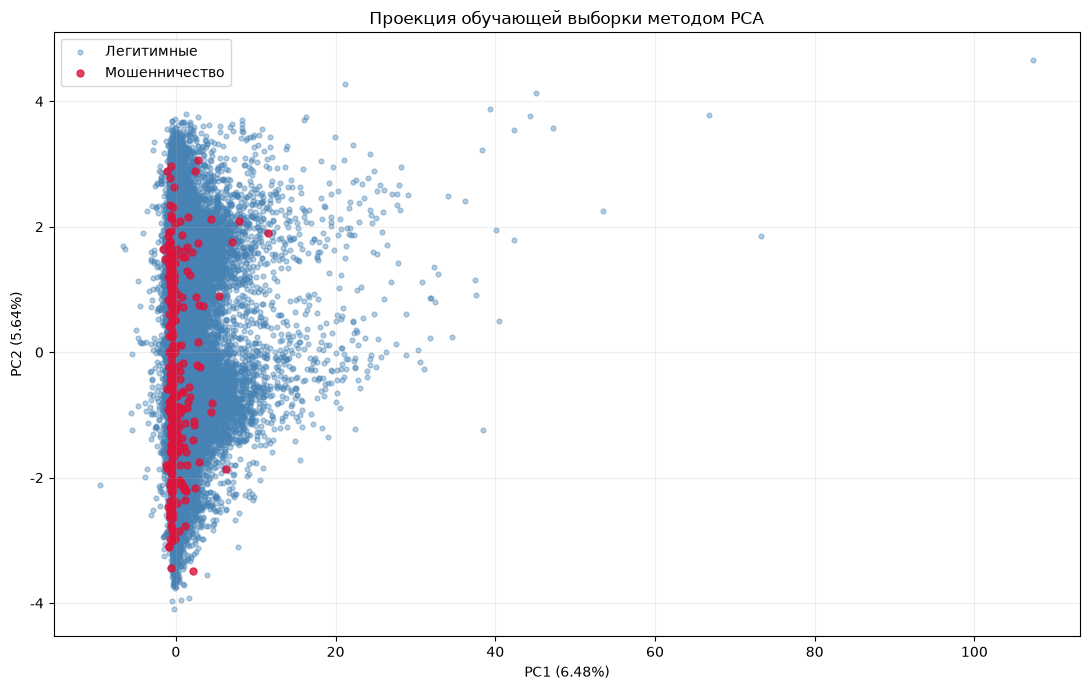

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))

colors = {0: "steelblue", 1: "crimson"}

for cls in [0, 1]:
    mask = (y_train.to_numpy() == cls)
    ax.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], c=colors[cls],
               label="Легитимные" if cls == 0 else "Мошенничество",
               alpha=0.4 if cls == 0 else 0.8, s=12 if cls == 0 else 25)

ax.set_title("Проекция обучающей выборки методом PCA")
ax.set_xlabel(f"PC1 ({explained[0] * 100:.2f}%)")
ax.set_ylabel(f"PC2 ({explained[1] * 100:.2f}%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(PICS_PATH / "6_pca_projection.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
rng = np.random.RandomState(random_state)
tsne_idx = rng.choice(len(X_train_vis), size=5000, replace=False)
tsne_sample = X_train_vis[tsne_idx]
tsne_labels = y_train.to_numpy()[tsne_idx]

tsne = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca", random_state=random_state)
X_tsne = tsne.fit_transform(tsne_sample)

print("Размерность после t-SNE:", X_tsne.shape)

Размерность после t-SNE: (5000, 2)


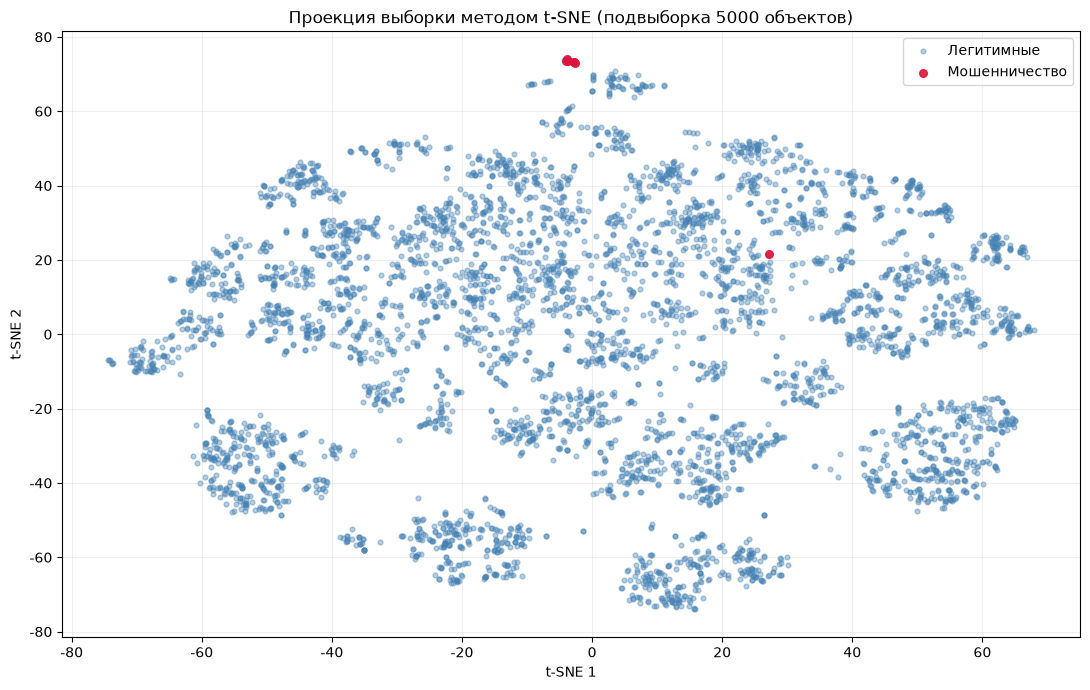

In [16]:
fig, ax = plt.subplots(figsize=(11, 7))

for cls in [0, 1]:
    mask = (tsne_labels == cls)
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=colors[cls],
               label="Легитимные" if cls == 0 else "Мошенничество",
               alpha=0.4 if cls == 0 else 0.9, s=12 if cls == 0 else 30)

ax.set_title("Проекция выборки методом t-SNE (подвыборка 5000 объектов)")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(PICS_PATH / "7_tsne_projection.png", dpi=300, bbox_inches="tight")
plt.show()

Первые две главные компоненты объясняют лишь небольшую часть дисперсии, мошеннические операции на проекции PCA не отделены от легитимных и образуют вытянутые хвосты. На проекции t-SNE малочисленный класс не образует отдельного плотного кластера, а рассеян среди остальных объектов. Это подтверждает, что простые линейные разделители дадут ограниченное качество и нужны нелинейные методы.

# 7. Классификация с параметрами по умолчанию

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=random_state))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier())
    ]),
    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(random_state=random_state))
    ]),
    "Random Forest": Pipeline([
        ("classifier", RandomForestClassifier(random_state=random_state))
    ]),
    "Gradient Boosting": Pipeline([
        ("classifier", GradientBoostingClassifier(random_state=random_state))
    ])
}

print("Созданы классификаторы:")
for name in models:
    print("-", name)

Созданы классификаторы:
- Logistic Regression
- KNN
- Decision Tree
- Random Forest
- Gradient Boosting


In [18]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "average_precision": "average_precision"
}

cv_results = []

for name, model in models.items():
    print(f"Кросс-валидация: {name}")
    scores = cross_validate(model, X_train_sub, y_train_sub, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Модель": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "PR-AUC": scores["test_average_precision"].mean()
    })

cv_table = pd.DataFrame(cv_results)
display(cv_table.round(4))

Кросс-валидация: Logistic Regression


Кросс-валидация: KNN


Кросс-валидация: Decision Tree


Кросс-валидация: Random Forest


Кросс-валидация: Gradient Boosting


,Модель,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.9990,0.7408,0.6213,0.6756,0.7283
1,KNN,0.9992,0.8095,0.6801,0.7391,0.7186
2,Decision Tree,0.9986,0.5732,0.6826,0.6222,0.4062
3,Random Forest,0.9993,0.8524,0.7010,0.7674,0.8345
4,Gradient Boosting,0.9988,0.6432,0.4436,0.5143,0.4111


In [19]:
default_predictions = {}
default_scores = {}
default_results = []

for name, model in models.items():
    model.fit(X_train_sub, y_train_sub)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    default_predictions[name] = y_pred
    default_scores[name] = y_score

    default_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, y_score)
    })

default_table = pd.DataFrame(default_results)
display(default_table.round(4))

default_table.to_csv(RESULTS_PATH / "results_default.csv", index=False, encoding="utf-8-sig")

,Модель,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.9989,0.7674,0.4648,0.5789,0.5660
1,KNN,0.9994,0.8879,0.7254,0.7984,0.7281
2,Decision Tree,0.9990,0.7231,0.6620,0.6912,0.4792
3,Random Forest,0.9994,0.9252,0.6972,0.7952,0.7882
4,Gradient Boosting,0.9990,0.7414,0.6056,0.6667,0.4670


In [20]:
for name, y_pred in default_predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

           0     0.9991    0.9998    0.9994     84976
           1     0.7674    0.4648    0.5789       142

    accuracy                         0.9989     85118
   macro avg     0.8833    0.7323    0.7892     85118
weighted avg     0.9987    0.9989    0.9987     85118

KNN
              precision    recall  f1-score   support

           0     0.9995    0.9998    0.9997     84976
           1     0.8879    0.7254    0.7984       142

    accuracy                         0.9994     85118
   macro avg     0.9437    0.8626    0.8991     85118
weighted avg     0.9994    0.9994    0.9994     85118

Decision Tree
              precision    recall  f1-score   support

           0     0.9994    0.9996    0.9995     84976
           1     0.7231    0.6620    0.6912       142

    accuracy                         0.9990     85118
   macro avg     0.8613    0.8308    0.8453     85118
weighted avg     0.9990    0.9990   

              precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     84976
           1     0.9252    0.6972    0.7952       142

    accuracy                         0.9994     85118
   macro avg     0.9624    0.8485    0.8974     85118
weighted avg     0.9994    0.9994    0.9994     85118

Gradient Boosting
              precision    recall  f1-score   support

           0     0.9993    0.9996    0.9995     84976
           1     0.7414    0.6056    0.6667       142

    accuracy                         0.9990     85118
   macro avg     0.8704    0.8026    0.8331     85118
weighted avg     0.9989    0.9990    0.9989     85118



Метрики Precision, Recall и F1 рассчитаны по положительному классу (мошенничество). Accuracy на таких данных малоинформативна: модель, всегда предсказывающая класс 0, даёт точность около 99.8%, но не находит ни одного мошенничества.

Для визуального сравнения тестовая выборка спроецирована в двумерное пространство PCA. Преобразование обучено на обучающей выборке. На следующих рисунках координаты точек фиксированы, меняется только цвет метки: слева исходный класс, справа предсказанный моделью.

In [21]:
X_test_vis = vis_scaler.transform(X_test)
X_test_pca = pca_vis.transform(X_test_vis)

y_test_array = y_test.to_numpy()

print("Размерность тестовой проекции:", X_test_pca.shape)
print("Объяснённая дисперсия:", round(explained.sum() * 100, 2), "%")

Размерность тестовой проекции: (85118, 2)
Объяснённая дисперсия: 12.12 %


In [22]:
def plot_test_comparison(y_original, y_pred, model_name):

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    datasets = [(y_original, "Исходные метки"), (y_pred, "Предсказанные метки")]

    for ax, (labels, title) in zip(axes, datasets):
        labels = np.asarray(labels)
        for cls in [0, 1]:
            mask = labels == cls
            ax.scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], c=colors[cls],
                       label="Легитимные" if cls == 0 else "Мошенничество",
                       alpha=0.4 if cls == 0 else 0.8, s=10 if cls == 0 else 25)
        ax.set_title(title)
        ax.set_xlabel(f"PC1 ({explained[0] * 100:.2f}%)")
        ax.set_ylabel(f"PC2 ({explained[1] * 100:.2f}%)")
        ax.legend()
        ax.grid(alpha=0.2)

    fig.suptitle(f"Сравнение исходных и предсказанных классов - {model_name}", fontsize=13)
    plt.tight_layout()

    filename = f"test_comparison_{model_name.lower().replace(' ', '_').replace('+', 'plus')}.png"
    fig.savefig(PICS_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

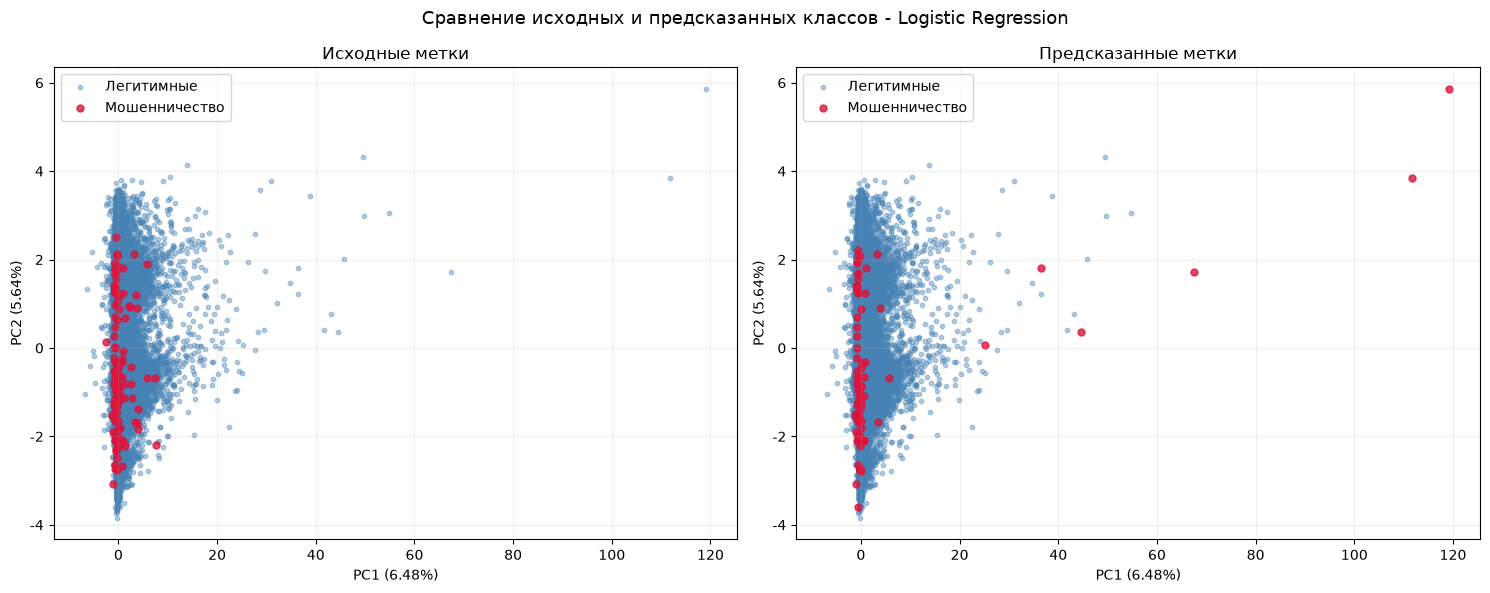

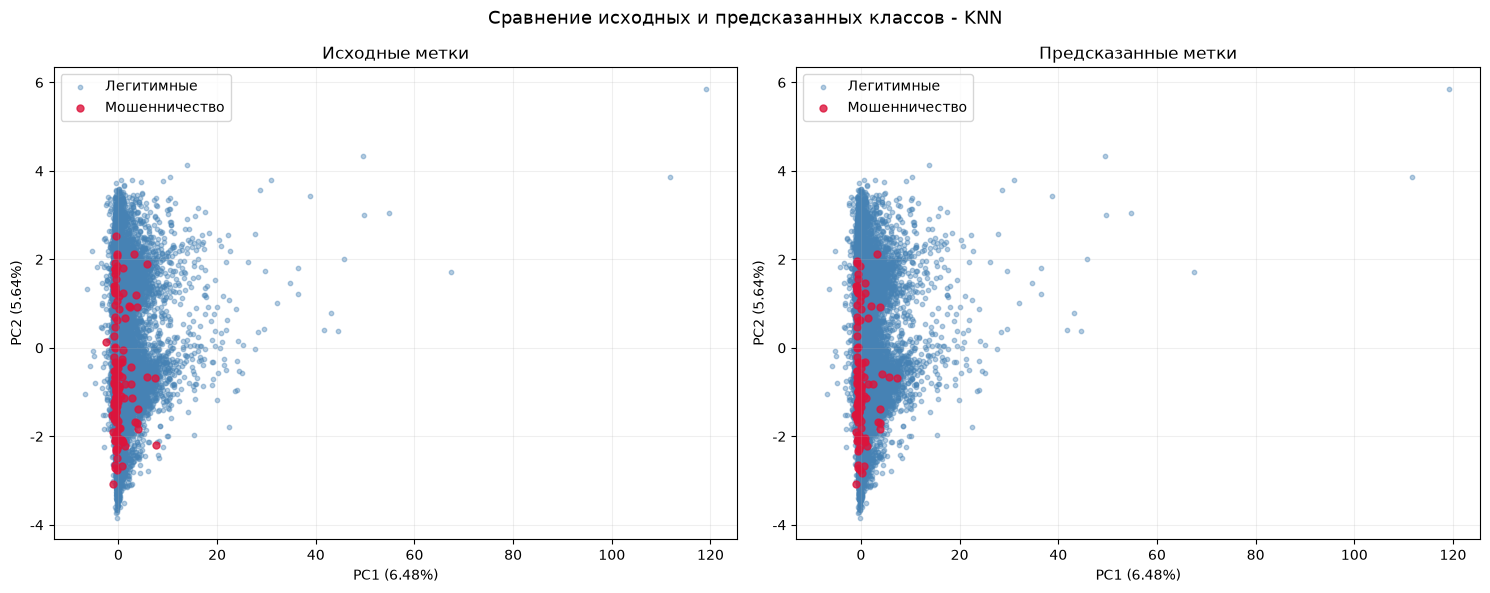

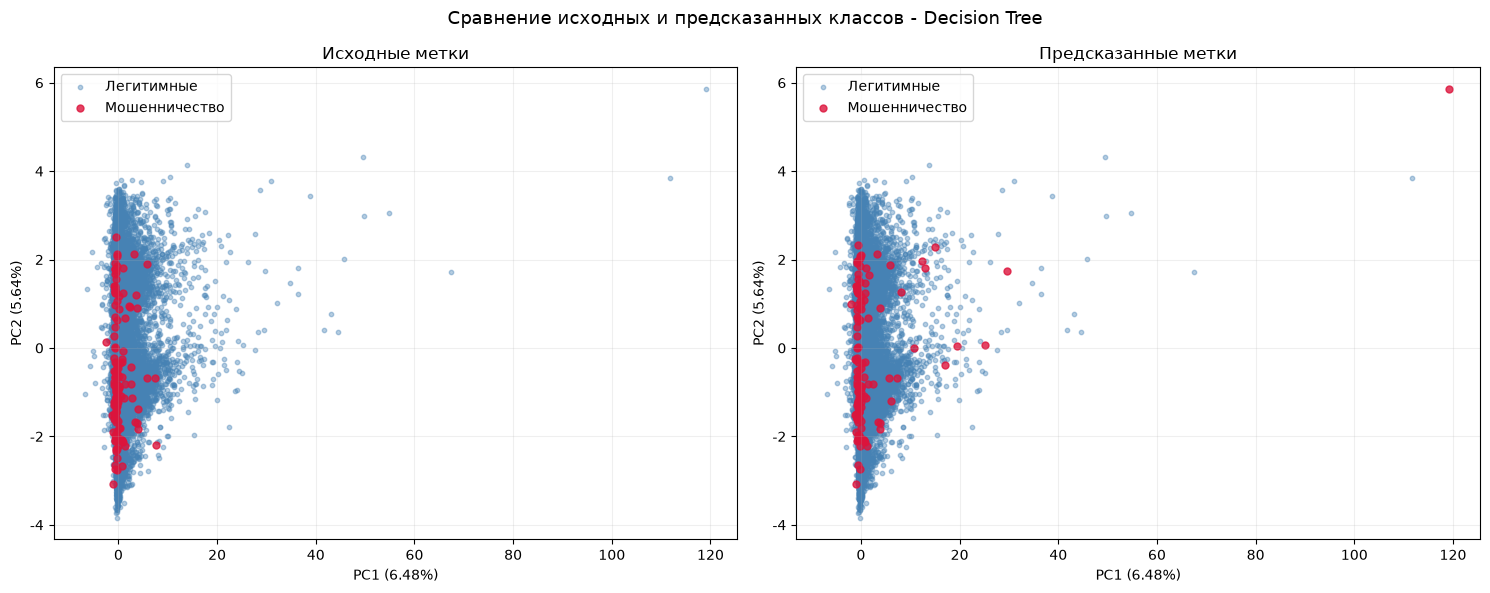

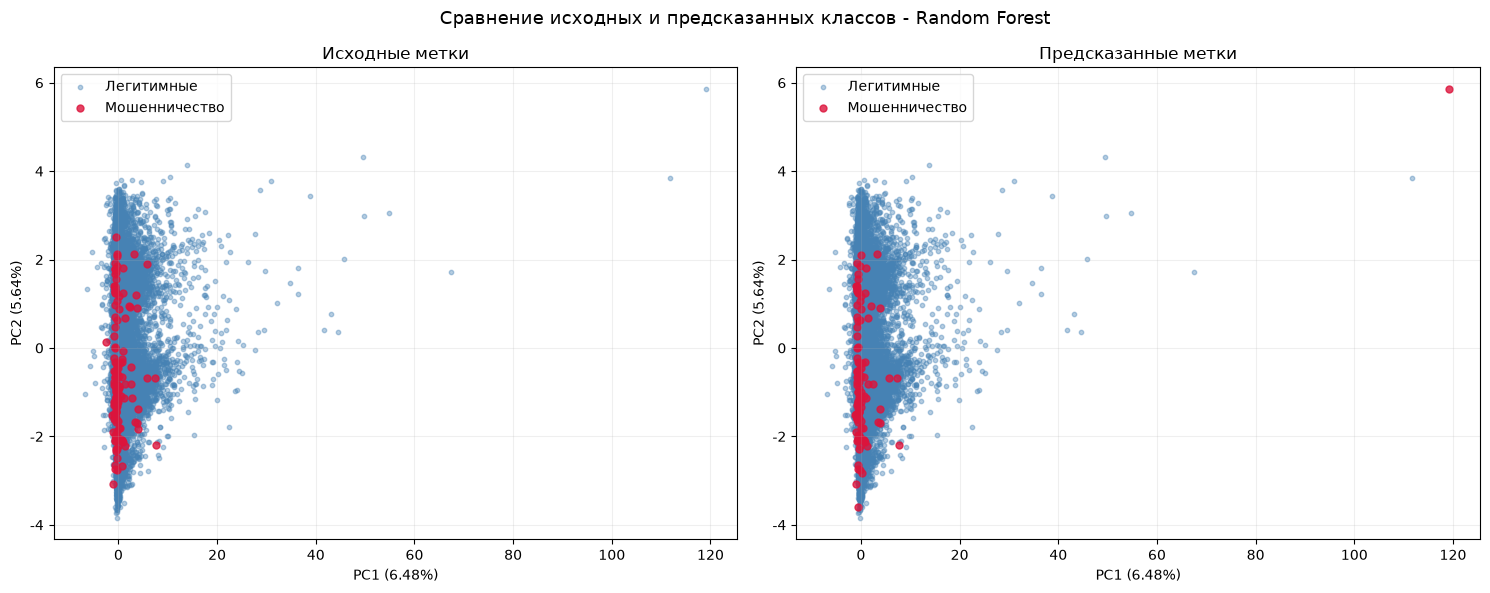

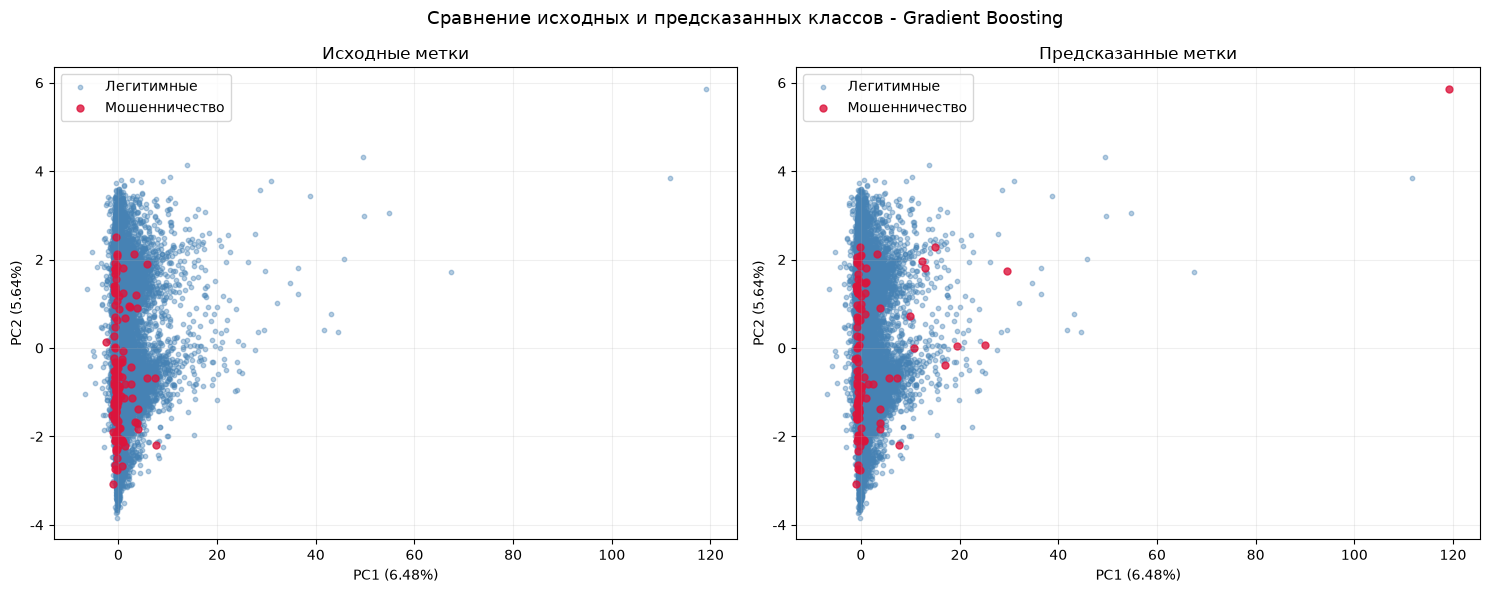

In [23]:
for name, y_pred in default_predictions.items():
    plot_test_comparison(y_test_array, y_pred, name)

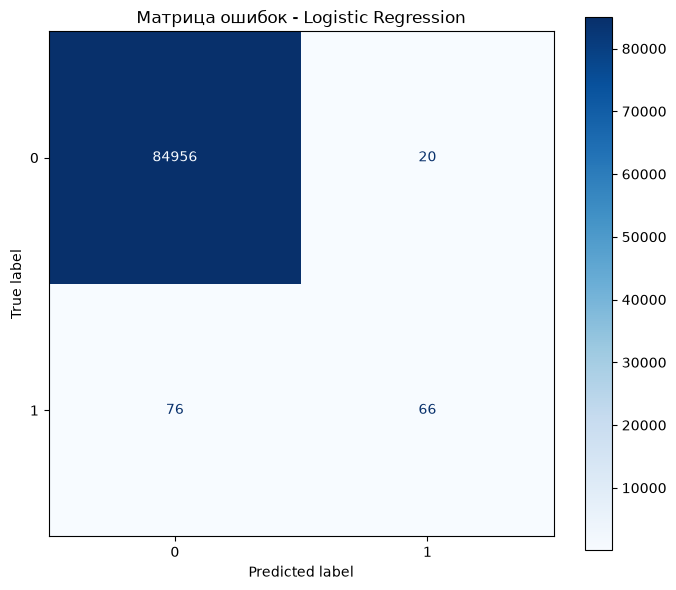

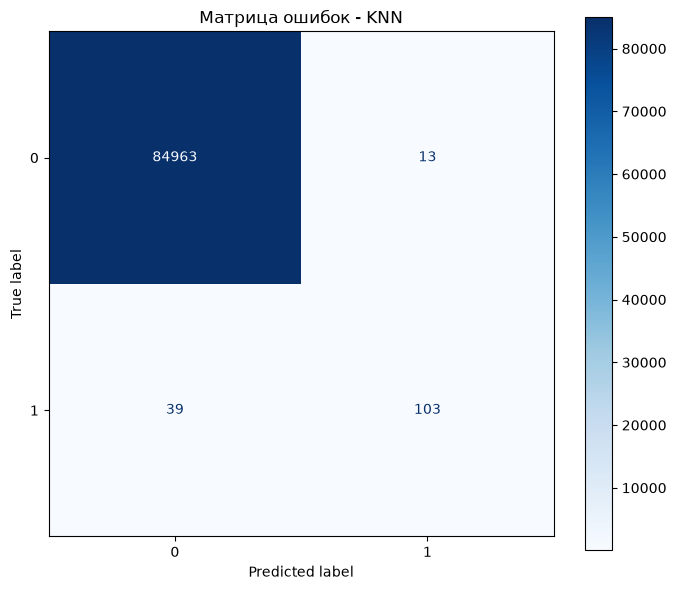

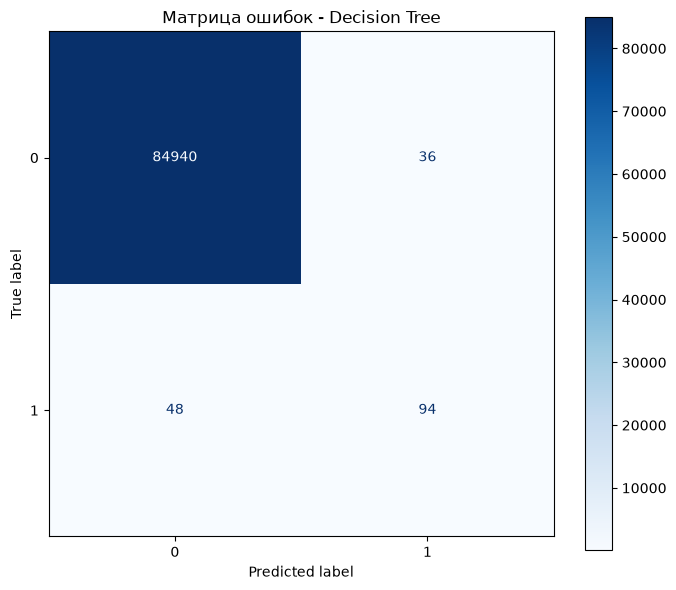

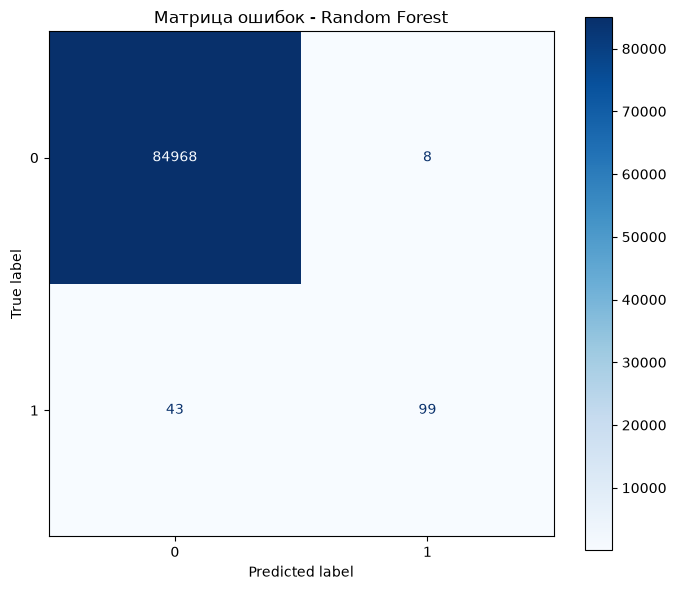

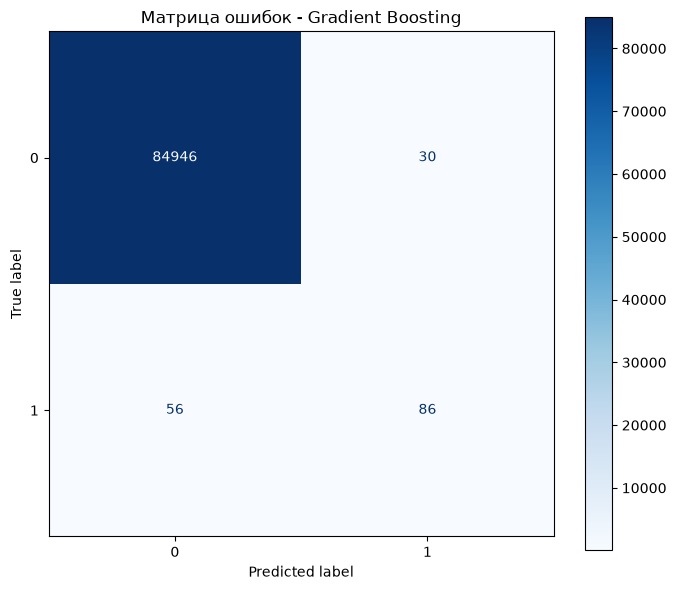

In [24]:
for name, y_pred in default_predictions.items():

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        labels=[0, 1], display_labels=["0", "1"],
        cmap="Blues", values_format="d", ax=ax
    )
    ax.set_title(f"Матрица ошибок - {name}")

    plt.tight_layout()

    filename = f"confusion_matrix_{name.lower().replace(' ', '_')}.png"
    fig.savefig(PICS_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

# 8. Обработка дисбаланса классов

In [25]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

imbalanced_models = {
    "Random Forest + SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=random_state)),
        ("classifier", RandomForestClassifier(random_state=random_state))
    ]),
    "Random Forest + Undersampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=random_state)),
        ("classifier", RandomForestClassifier(random_state=random_state))
    ]),
    "Gradient Boosting + SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=random_state)),
        ("classifier", GradientBoostingClassifier(random_state=random_state))
    ])
}

print("Созданы модели с балансировкой:")
for name in imbalanced_models:
    print("-", name)

Созданы модели с балансировкой:
- Random Forest + SMOTE
- Random Forest + Undersampling
- Gradient Boosting + SMOTE


In [26]:
imbalanced_results = []
imbalanced_predictions = {}
imbalanced_scores = {}

for name, model in imbalanced_models.items():
    print(f"Обучение: {name}")
    model.fit(X_train_sub, y_train_sub)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    imbalanced_predictions[name] = y_pred
    imbalanced_scores[name] = y_score

    imbalanced_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, y_score)
    })

imbalanced_table = pd.DataFrame(imbalanced_results)
display(imbalanced_table.round(4))

Обучение: Random Forest + SMOTE


Обучение: Random Forest + Undersampling


Обучение: Gradient Boosting + SMOTE


,Модель,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Random Forest + SMOTE,0.9993,0.8435,0.6831,0.7549,0.7752
1,Random Forest + Undersampling,0.9720,0.0491,0.8592,0.0928,0.6075
2,Gradient Boosting + SMOTE,0.9970,0.3284,0.7817,0.4625,0.6470


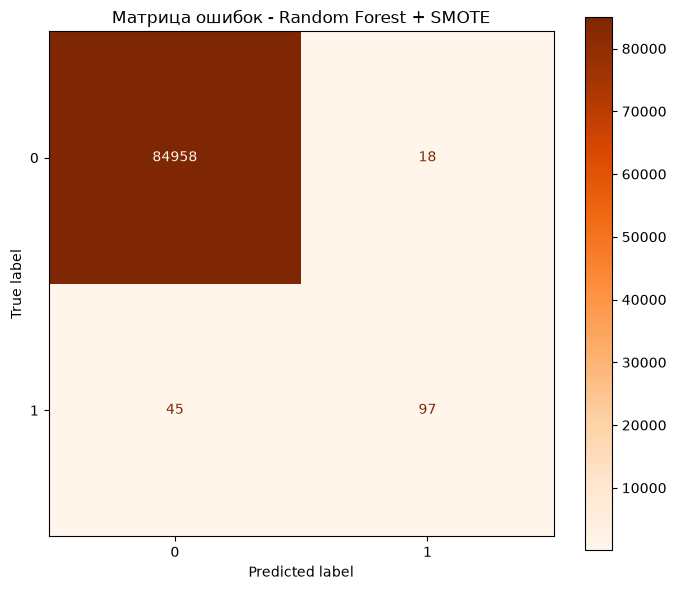

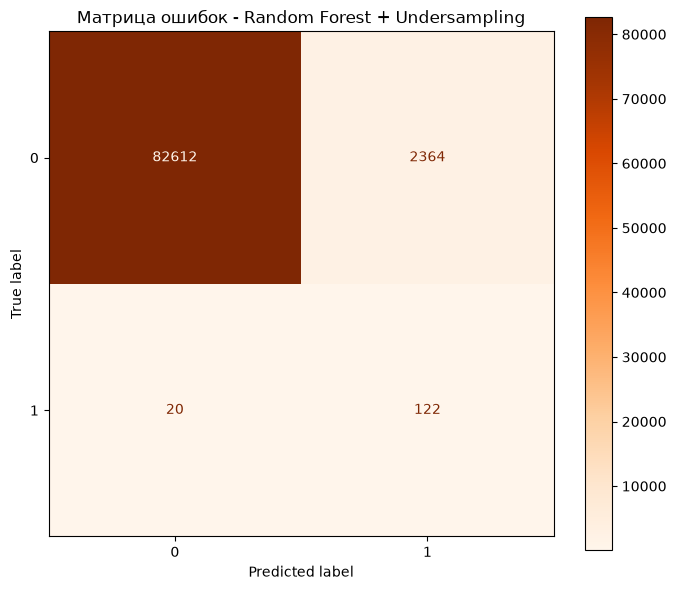

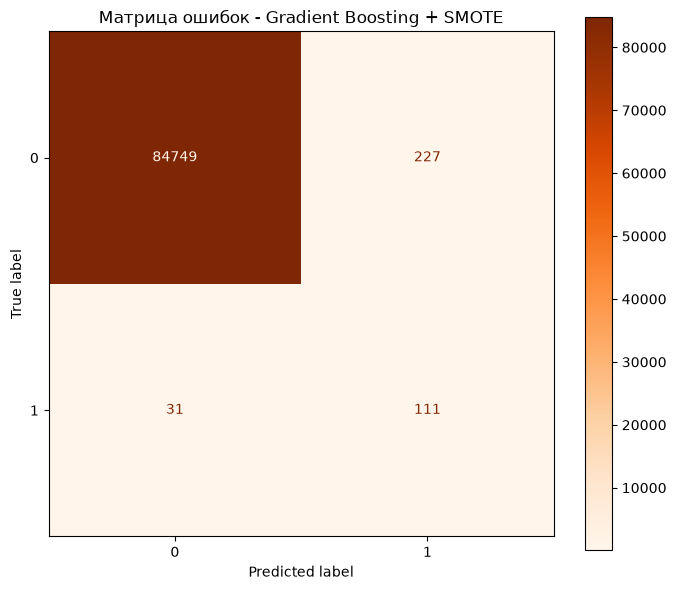

In [27]:
for name, y_pred in imbalanced_predictions.items():

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        labels=[0, 1], display_labels=["0", "1"],
        cmap="Oranges", values_format="d", ax=ax
    )
    ax.set_title(f"Матрица ошибок - {name}")

    plt.tight_layout()

    filename = f"confusion_{name.lower().replace(' ', '_').replace('+', 'plus')}.png"
    fig.savefig(PICS_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

SMOTE создаёт синтетические объекты малочисленного класса, undersampling сокращает число объектов многочисленного класса. Балансировка выполняется только на обучающей выборке, тестовая выборка остаётся несбалансированной, поэтому метрики отражают поведение модели на реальном распределении.

# 9. Метод поиска аномалий (Isolation Forest)

In [28]:
from sklearn.ensemble import IsolationForest

iso_scaler = StandardScaler()
X_train_iso = iso_scaler.fit_transform(X_train)
X_test_iso = iso_scaler.transform(X_test)

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.002,
    random_state=random_state
)
iso_forest.fit(X_train_iso)

iso_pred = (iso_forest.predict(X_test_iso) == -1).astype(int)
iso_score = -iso_forest.score_samples(X_test_iso)

iso_results = pd.DataFrame([{
    "Модель": "Isolation Forest",
    "Accuracy": accuracy_score(y_test, iso_pred),
    "Precision": precision_score(y_test, iso_pred, zero_division=0),
    "Recall": recall_score(y_test, iso_pred, zero_division=0),
    "F1-score": f1_score(y_test, iso_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, iso_score)
}])

display(iso_results.round(4))

,Модель,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Isolation Forest,0.9973,0.2424,0.2817,0.2606,0.1335


Isolation Forest обучается без меток и ищет нетипичные объекты. Число найденных аномалий задаётся параметром contamination. На рассматриваемых данных метод даёт много ложных срабатываний, поскольку распределение мошенничеств пересекается с легитимными операциями.

# 10. Сравнение всех методов по умолчанию

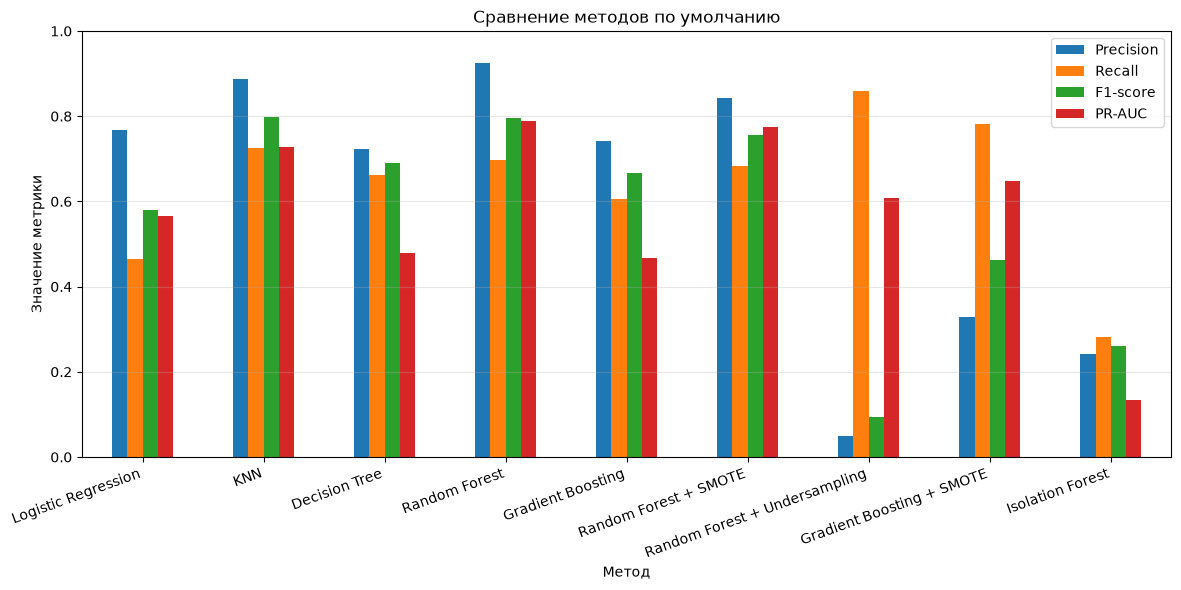

,Модель,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.9989,0.7674,0.4648,0.5789,0.5660
1,KNN,0.9994,0.8879,0.7254,0.7984,0.7281
2,Decision Tree,0.9990,0.7231,0.6620,0.6912,0.4792
3,Random Forest,0.9994,0.9252,0.6972,0.7952,0.7882
4,Gradient Boosting,0.9990,0.7414,0.6056,0.6667,0.4670
5,Random Forest + SMOTE,0.9993,0.8435,0.6831,0.7549,0.7752
6,Random Forest + Undersampling,0.9720,0.0491,0.8592,0.0928,0.6075
7,Gradient Boosting + SMOTE,0.9970,0.3284,0.7817,0.4625,0.6470
8,Isolation Forest,0.9973,0.2424,0.2817,0.2606,0.1335


In [29]:
all_default = pd.concat([default_table, imbalanced_table, iso_results], ignore_index=True)

fig, ax = plt.subplots(figsize=(12, 6))

metrics = ["Precision", "Recall", "F1-score", "PR-AUC"]
all_default.set_index("Модель")[metrics].plot(kind="bar", ax=ax)

ax.set_title("Сравнение методов по умолчанию")
ax.set_xlabel("Метод")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0, 1)
ax.set_xticklabels(all_default["Модель"], rotation=20, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
fig.savefig(PICS_PATH / "8_comparison_default.png", dpi=300, bbox_inches="tight")
plt.show()

display(all_default.round(4))

all_default.to_csv(RESULTS_PATH / "results_default_all.csv", index=False, encoding="utf-8-sig")

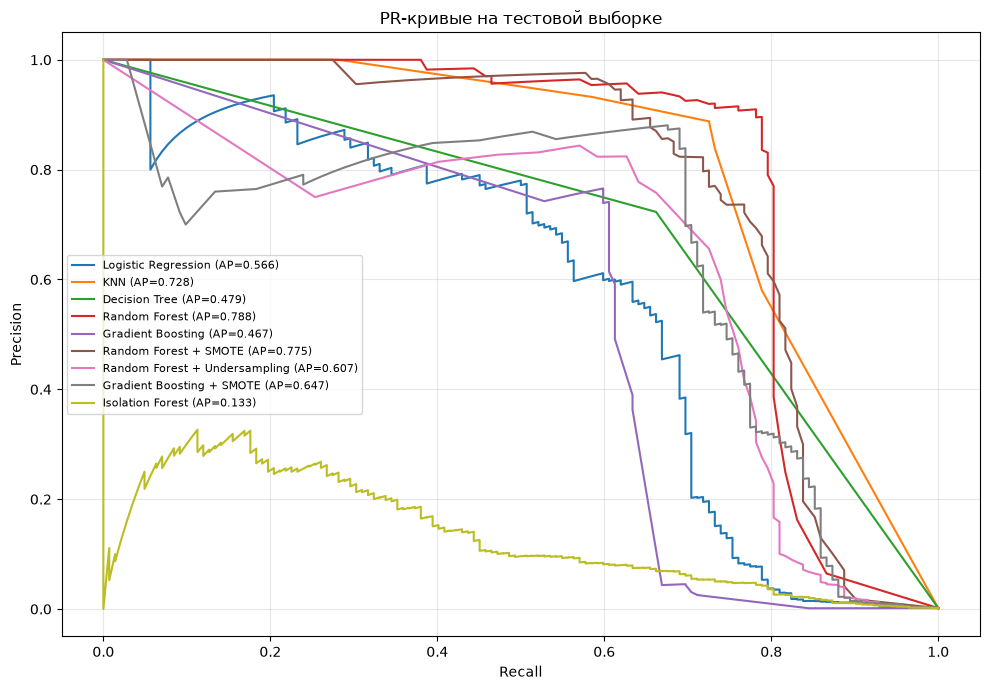

In [30]:
fig, ax = plt.subplots(figsize=(10, 7))

all_scores = {**default_scores, **imbalanced_scores, "Isolation Forest": iso_score}

for name, scores in all_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

ax.set_title("PR-кривые на тестовой выборке")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig(PICS_PATH / "9_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# 11. Настройка гиперпараметров (GridSearchCV)

In [31]:
from sklearn.model_selection import GridSearchCV

tree_params = {
    "classifier__max_depth": [5, 10]
}

forest_params = {
    "classifier__n_estimators": [100, 200]
}

boosting_params = {
    "classifier__n_estimators": [100, 200]
}

knn_params = {
    "classifier__n_neighbors": [5, 7]
}

logreg_params = {
    "classifier__C": [0.1, 1.0]
}

param_grids = {
    "Logistic Regression": logreg_params,
    "KNN": knn_params,
    "Decision Tree": tree_params,
    "Random Forest": forest_params,
    "Gradient Boosting": boosting_params
}

In [32]:
grid_searches = {}
best_models = {}
grid_summary = []
all_grid_results = []

for name, model in models.items():
    print("=" * 60)
    print("Настройка модели:", name)
    print("=" * 60)

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="f1",
        refit=True,
        cv=cv,
        n_jobs=-1
    )
    search.fit(X_train_sub, y_train_sub)

    grid_searches[name] = search
    best_models[name] = search.best_estimator_

    grid_summary.append({
        "Модель": name,
        "F1-score": search.best_score_,
        "Лучшие параметры": str(search.best_params_)
    })

    results = pd.DataFrame(search.cv_results_)
    results["Модель"] = name
    all_grid_results.append(results)

    print("Лучшие параметры:", search.best_params_)
    print("Лучший F1:", round(search.best_score_, 4))

Настройка модели: Logistic Regression


Лучшие параметры: {'classifier__C': 0.1}
Лучший F1: 0.6779
Настройка модели: KNN


Лучшие параметры: {'classifier__n_neighbors': 7}
Лучший F1: 0.7611
Настройка модели: Decision Tree


Лучшие параметры: {'classifier__max_depth': 5}
Лучший F1: 0.6627
Настройка модели: Random Forest


Лучшие параметры: {'classifier__n_estimators': 100}
Лучший F1: 0.7674
Настройка модели: Gradient Boosting


Лучшие параметры: {'classifier__n_estimators': 200}
Лучший F1: 0.5159


In [33]:
grid_table = pd.DataFrame(grid_summary).sort_values(by="F1-score", ascending=False)

display(grid_table.round(4))

with open(RESULTS_PATH / "best_params.json", "w", encoding="utf-8") as file:
    json.dump({name: search.best_params_ for name, search in grid_searches.items()}, file, ensure_ascii=False, indent=4)

grid_table.to_csv(RESULTS_PATH / "gridsearch_best_results.csv", index=False, encoding="utf-8-sig")
pd.concat(all_grid_results, ignore_index=True).to_csv(RESULTS_PATH / "gridsearch_all_results.csv", index=False, encoding="utf-8-sig")

,Модель,F1-score,Лучшие параметры
3,Random Forest,0.7674,{'classifier__n_estimators': 100}
1,KNN,0.7611,{'classifier__n_neighbors': 7}
0,Logistic Regression,0.6779,{'classifier__C': 0.1}
2,Decision Tree,0.6627,{'classifier__max_depth': 5}
4,Gradient Boosting,0.5159,{'classifier__n_estimators': 200}


Критерий выбора гиперпараметров - средняя F1-мера на кросс-валидации, то есть приоритет отдан поиску мошенничества. Тестовая выборка при настройке не используется.

# 12. Классификация с подобранными параметрами

In [34]:
import joblib

tuned_predictions = {}
tuned_scores = {}
tuned_results = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    tuned_predictions[name] = y_pred
    tuned_scores[name] = y_score

    tuned_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, y_score)
    })

tuned_table = pd.DataFrame(tuned_results)
display(tuned_table.round(4))

joblib.dump(best_models, RESULTS_PATH / "best_models.joblib")

tuned_table.to_csv(RESULTS_PATH / "optimized_results.csv", index=False, encoding="utf-8-sig")

,Модель,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.9988,0.7792,0.4225,0.5479,0.6123
1,KNN,0.9993,0.8374,0.7254,0.7774,0.7244
2,Decision Tree,0.9992,0.7966,0.6620,0.7231,0.5279
3,Random Forest,0.9994,0.9252,0.6972,0.7952,0.7882
4,Gradient Boosting,0.9990,0.7414,0.6056,0.6667,0.5104


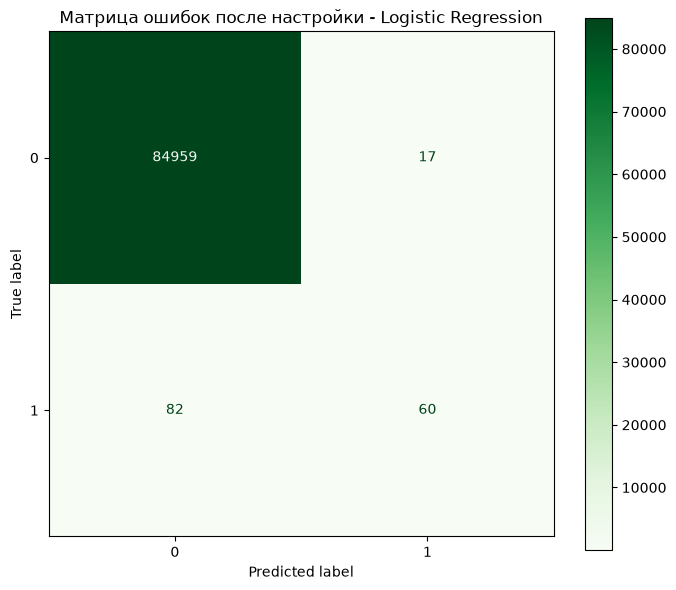

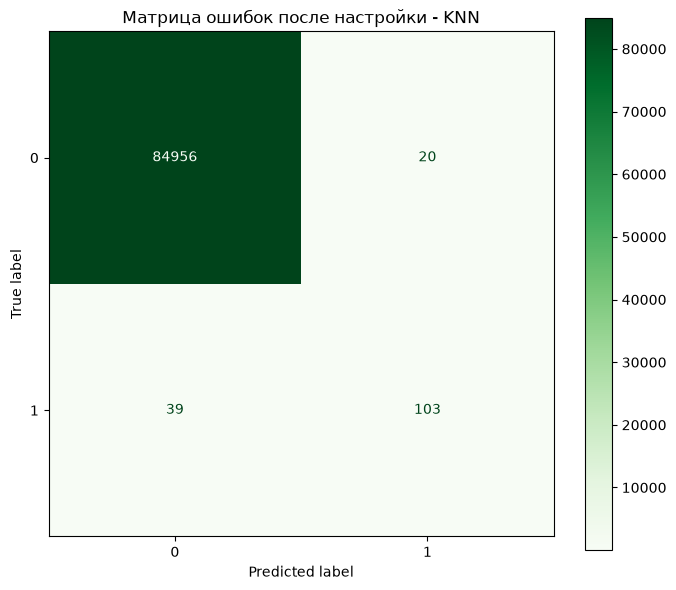

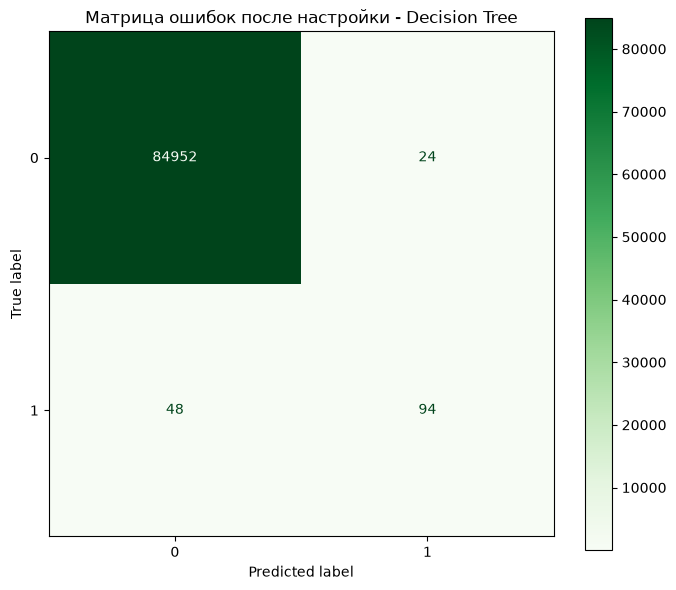

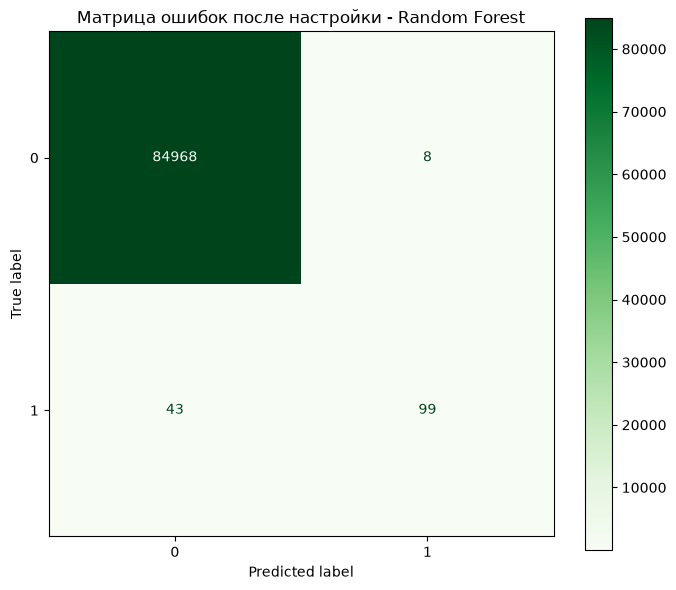

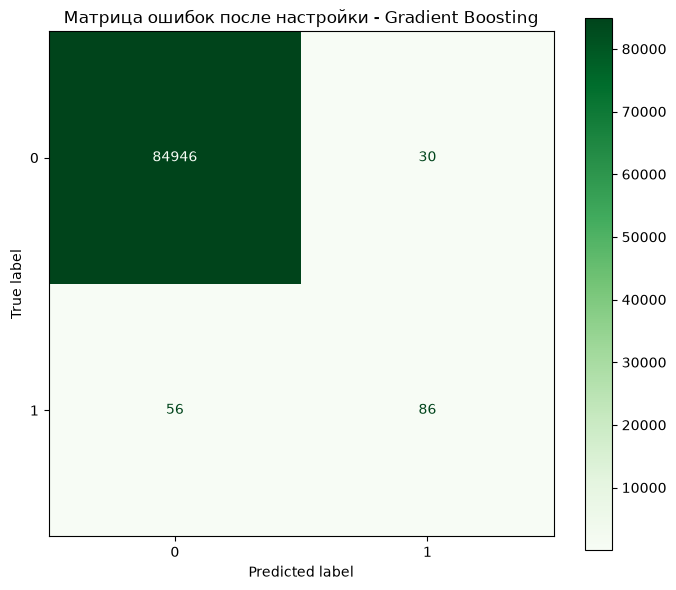

In [35]:
for name, y_pred in tuned_predictions.items():

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        labels=[0, 1], display_labels=["0", "1"],
        cmap="Greens", values_format="d", ax=ax
    )
    ax.set_title(f"Матрица ошибок после настройки - {name}")

    plt.tight_layout()

    filename = f"optimized_confusion_{name.lower().replace(' ', '_')}.png"
    fig.savefig(PICS_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

In [36]:
def plot_optimized_comparison(y_original, y_default, y_optimized, model_name):

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    datasets = [
        (y_original, "Исходные метки"),
        (y_default, "Предсказания до настройки"),
        (y_optimized, "Предсказания после настройки")
    ]

    for ax, (labels, title) in zip(axes, datasets):
        labels = np.asarray(labels)
        for cls in [0, 1]:
            mask = labels == cls
            ax.scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], c=colors[cls],
                       label="Легитимные" if cls == 0 else "Мошенничество",
                       alpha=0.4 if cls == 0 else 0.8, s=10 if cls == 0 else 25)
        ax.set_title(title)
        ax.set_xlabel(f"PC1 ({explained[0] * 100:.2f}%)")
        ax.set_ylabel(f"PC2 ({explained[1] * 100:.2f}%)")
        ax.legend()
        ax.grid(alpha=0.2)

    fig.suptitle(f"Сравнение классификации - {model_name}", fontsize=14)
    plt.tight_layout()

    filename = f"optimized_comparison_{model_name.lower().replace(' ', '_')}.png"
    fig.savefig(PICS_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

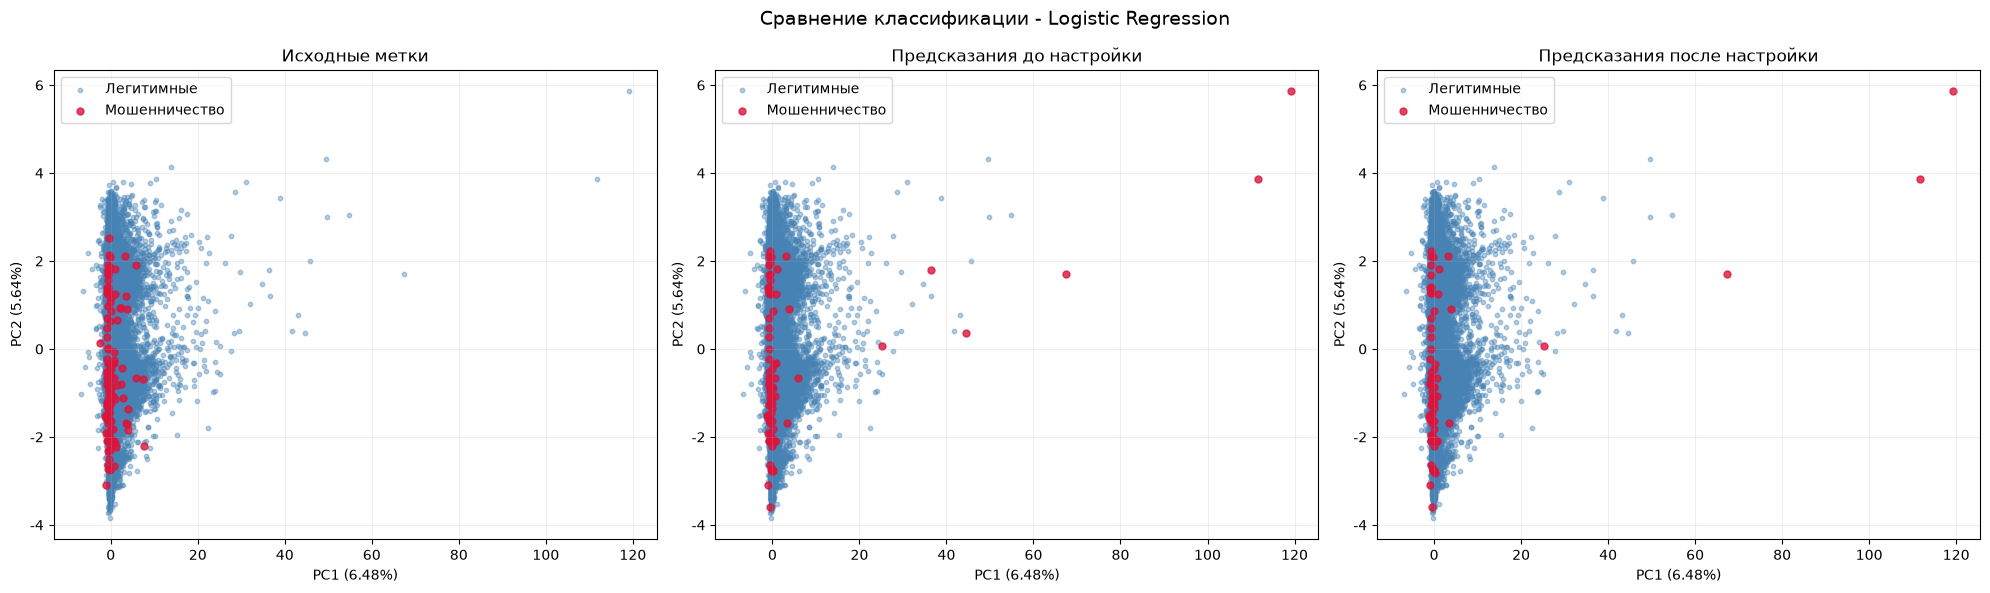

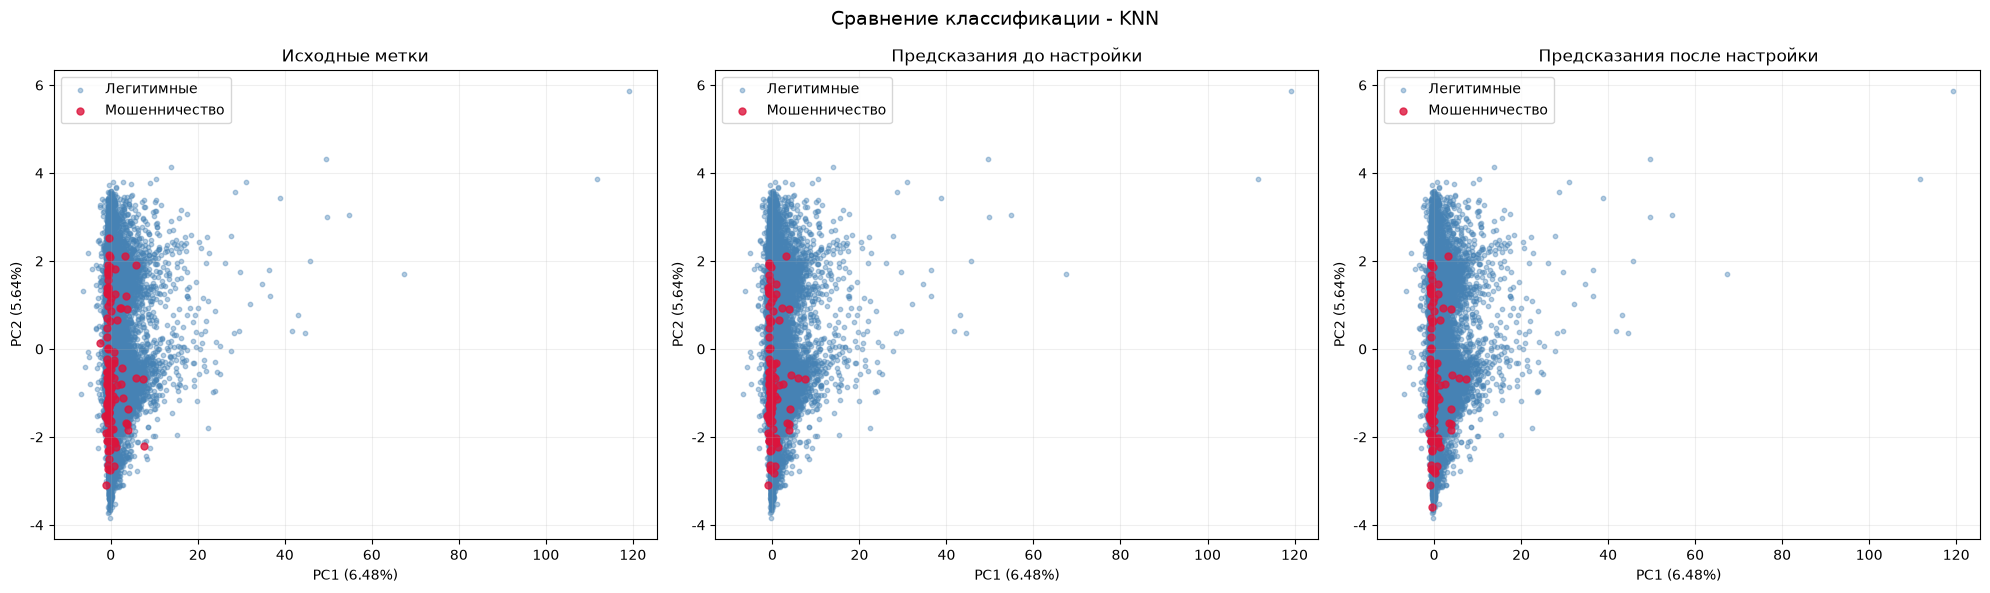

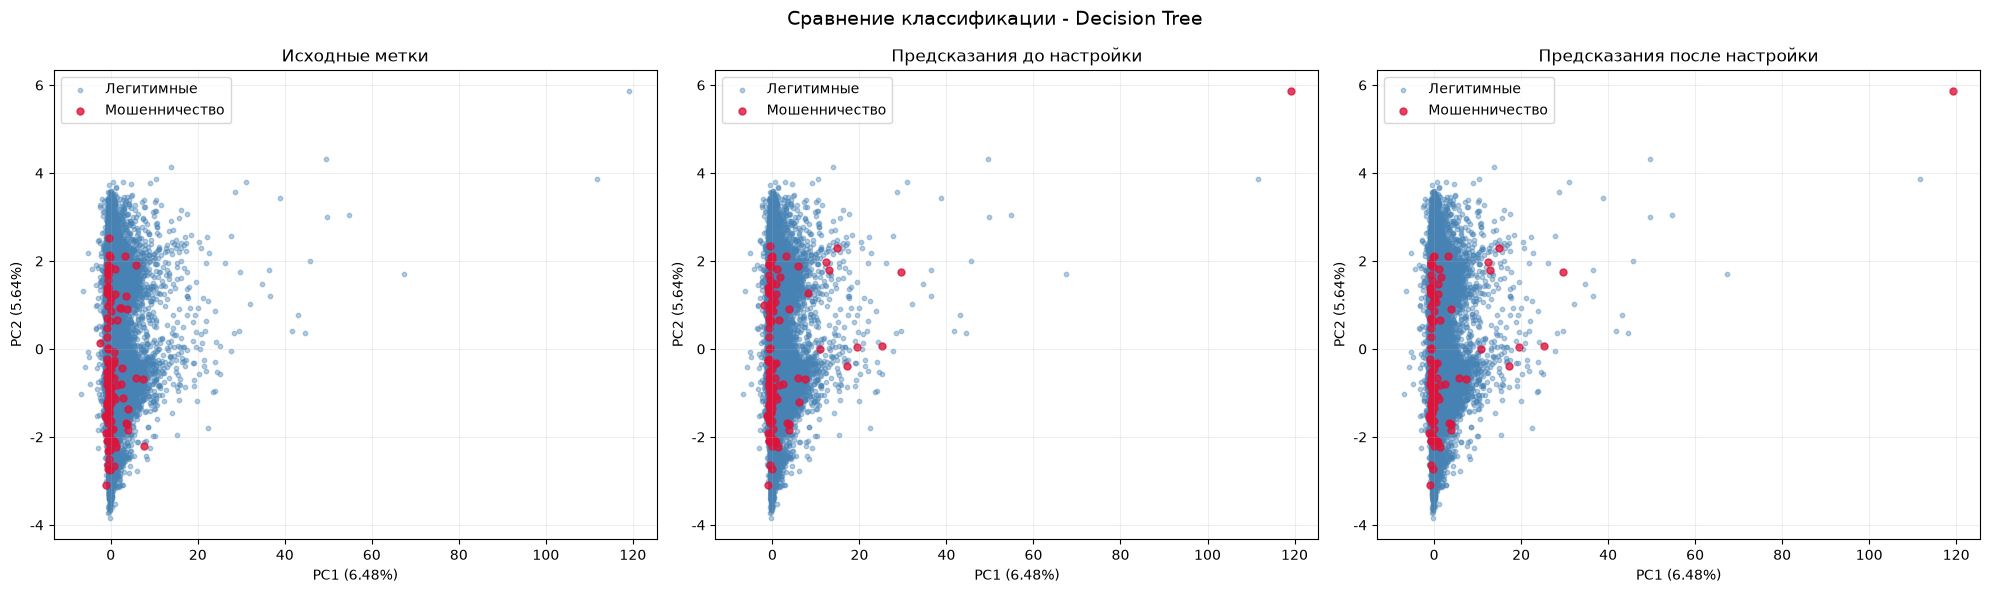

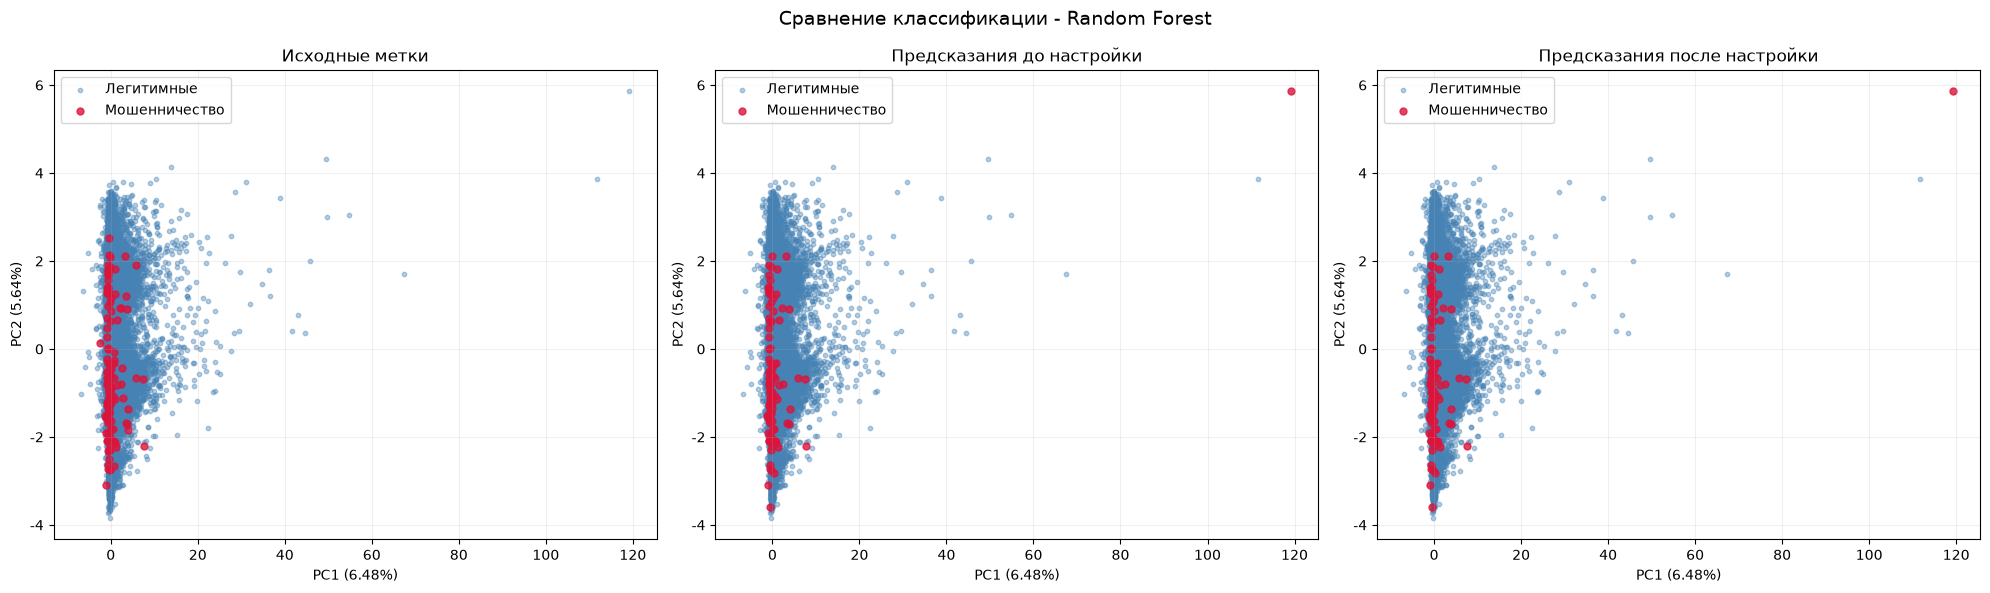

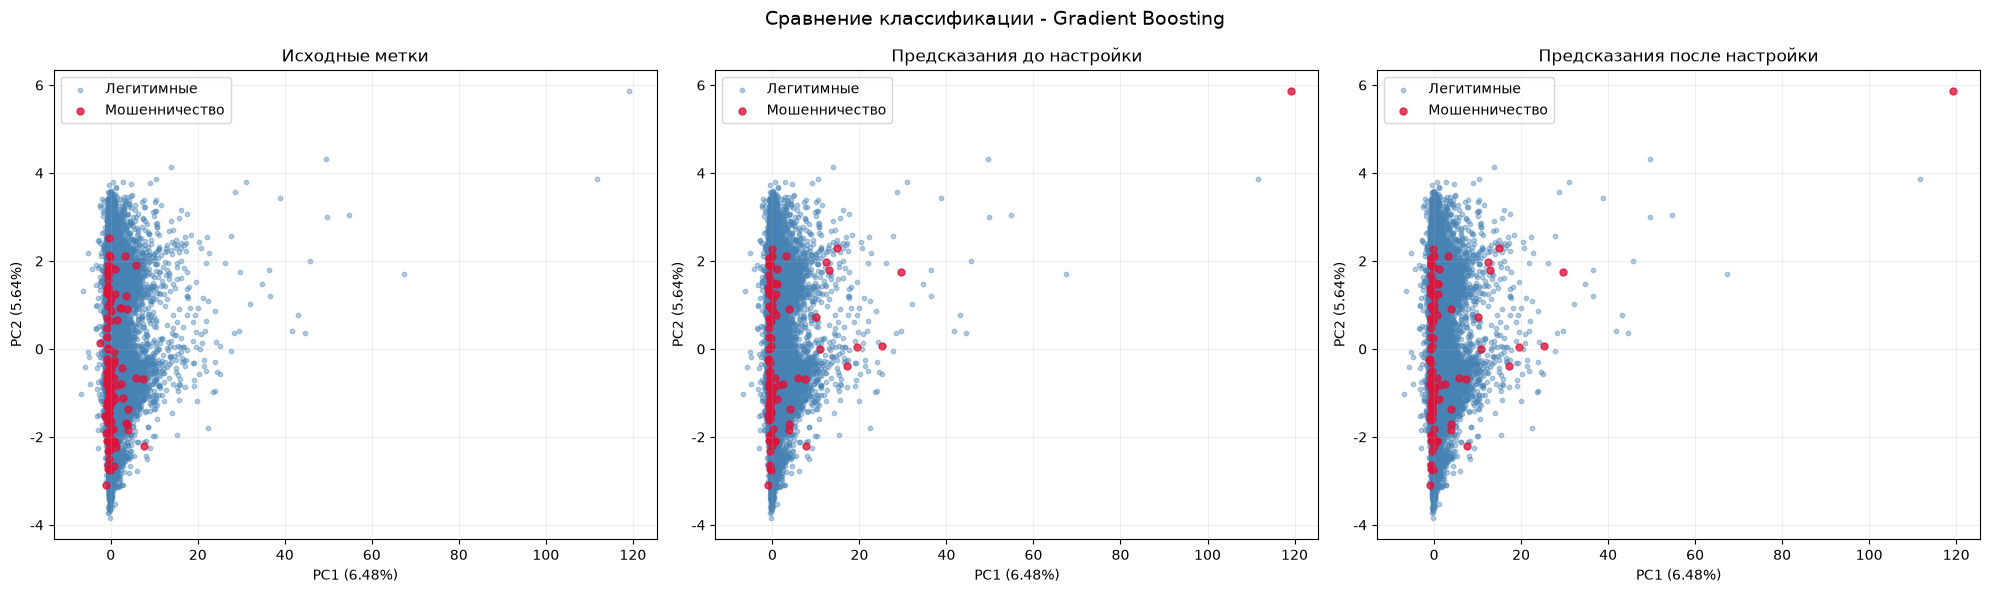

In [37]:
for name in default_predictions:
    plot_optimized_comparison(
        y_test_array,
        default_predictions[name],
        tuned_predictions[name],
        name
    )

In [38]:
comparison = default_table.merge(tuned_table, on="Модель", suffixes=("_до", "_после"))

for metric in ["F1-score", "Recall", "PR-AUC"]:
    comparison[f"{metric}_изменение"] = comparison[f"{metric}_после"] - comparison[f"{metric}_до"]

display(comparison.round(4))

comparison.to_csv(RESULTS_PATH / "comparison_before_after.csv", index=False, encoding="utf-8-sig")

,Модель,Accuracy_до,Precision_до,Recall_до,F1-score_до,PR-AUC_до,Accuracy_после,Precision_после,Recall_после,F1-score_после,PR-AUC_после,F1-score_изменение,Recall_изменение,PR-AUC_изменение
0,Logistic Regression,0.9989,0.7674,0.4648,0.5789,0.5660,0.9988,0.7792,0.4225,0.5479,0.6123,-0.0310,-0.0423,0.0463
1,KNN,0.9994,0.8879,0.7254,0.7984,0.7281,0.9993,0.8374,0.7254,0.7774,0.7244,-0.0211,0.0000,-0.0037
2,Decision Tree,0.9990,0.7231,0.6620,0.6912,0.4792,0.9992,0.7966,0.6620,0.7231,0.5279,0.0319,0.0000,0.0486
3,Random Forest,0.9994,0.9252,0.6972,0.7952,0.7882,0.9994,0.9252,0.6972,0.7952,0.7882,0.0000,0.0000,0.0000
4,Gradient Boosting,0.9990,0.7414,0.6056,0.6667,0.4670,0.9990,0.7414,0.6056,0.6667,0.5104,0.0000,0.0000,0.0435


/tmp/ipykernel_27921/3916112982.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels, rotation=20, ha="right")


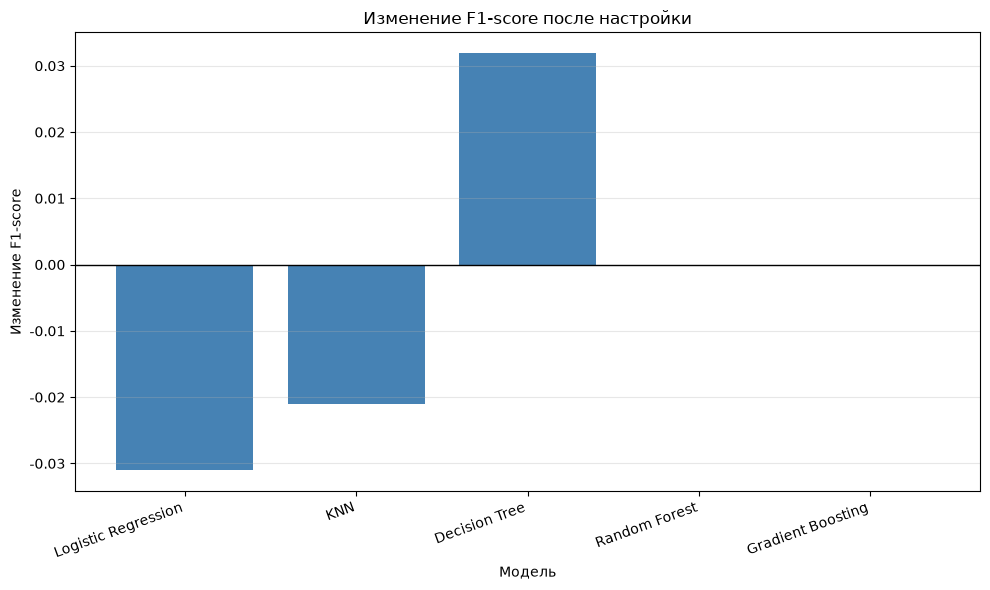

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))

labels = comparison["Модель"]
ax.bar(labels, comparison["F1-score_изменение"], color="steelblue")
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Изменение F1-score после настройки")
ax.set_xlabel("Модель")
ax.set_ylabel("Изменение F1-score")
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(PICS_PATH / "10_f1_improvement.png", dpi=300, bbox_inches="tight")
plt.show()

# 13. Итоговое сравнение всех методов

In [40]:
final_all = pd.concat([
    default_table.assign(Этап="По умолчанию"),
    imbalanced_table.assign(Этап="С балансировкой"),
    iso_results.assign(Этап="Без учителя"),
    tuned_table.assign(Этап="После настройки")
], ignore_index=True)

final_all = final_all[["Модель", "Этап", "Accuracy", "Precision", "Recall", "F1-score", "PR-AUC"]]
final_all = final_all.sort_values(by="F1-score", ascending=False).reset_index(drop=True)

display(final_all.round(4))

final_all.to_csv(RESULTS_PATH / "final_comparison.csv", index=False, encoding="utf-8-sig")

,Модель,Этап,Accuracy,Precision,Recall,F1-score,PR-AUC
0,KNN,По умолчанию,0.9994,0.8879,0.7254,0.7984,0.7281
1,Random Forest,По умолчанию,0.9994,0.9252,0.6972,0.7952,0.7882
2,Random Forest,После настройки,0.9994,0.9252,0.6972,0.7952,0.7882
3,KNN,После настройки,0.9993,0.8374,0.7254,0.7774,0.7244
4,Random Forest + SMOTE,С балансировкой,0.9993,0.8435,0.6831,0.7549,0.7752
5,Decision Tree,После настройки,0.9992,0.7966,0.6620,0.7231,0.5279
6,Decision Tree,По умолчанию,0.9990,0.7231,0.6620,0.6912,0.4792
7,Gradient Boosting,По умолчанию,0.9990,0.7414,0.6056,0.6667,0.4670
8,Gradient Boosting,После настройки,0.9990,0.7414,0.6056,0.6667,0.5104
9,Logistic Regression,По умолчанию,0.9989,0.7674,0.4648,0.5789,0.5660


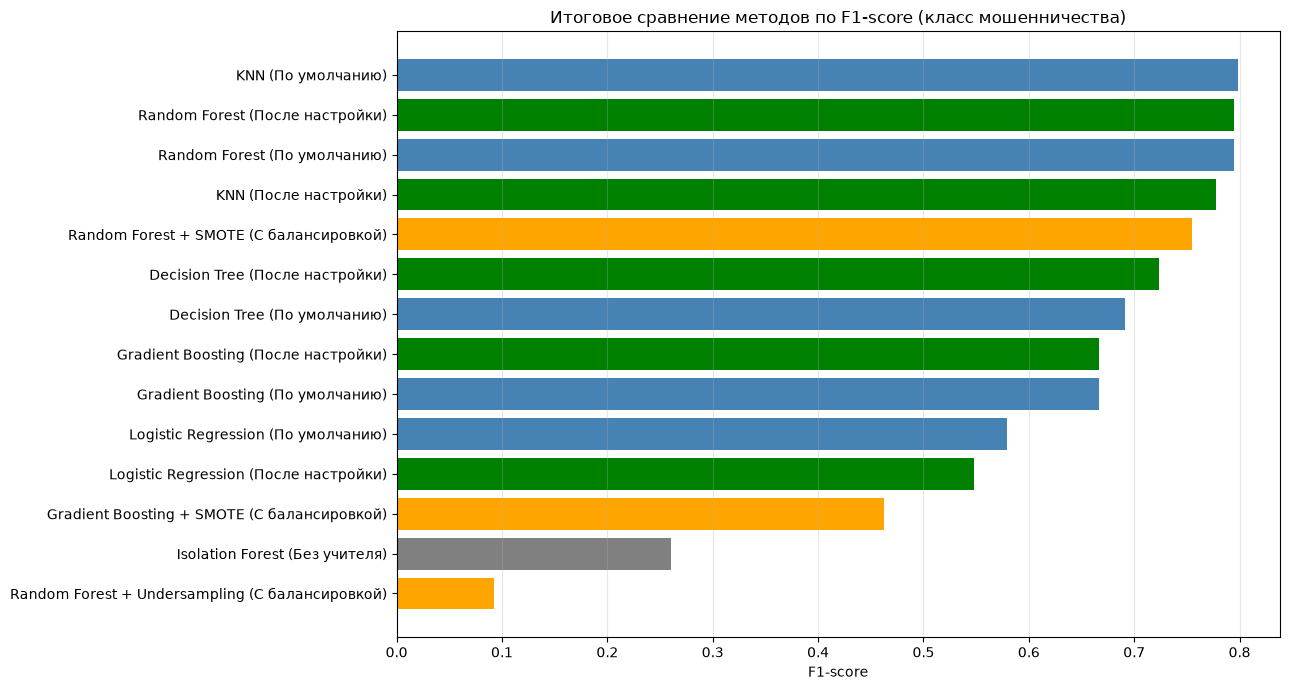

In [41]:
fig, ax = plt.subplots(figsize=(13, 7))

sorted_final = final_all.sort_values(by="F1-score")
plot_colors = sorted_final["Этап"].map({
    "По умолчанию": "steelblue",
    "С балансировкой": "orange",
    "Без учителя": "gray",
    "После настройки": "green"
})

ax.barh(sorted_final["Модель"] + " (" + sorted_final["Этап"] + ")", sorted_final["F1-score"], color=plot_colors)
ax.set_title("Итоговое сравнение методов по F1-score (класс мошенничества)")
ax.set_xlabel("F1-score")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
fig.savefig(PICS_PATH / "11_final_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
best_row = final_all.iloc[0]

print("Лучший результат по F1-score:")
print(best_row["Модель"], "-", best_row["Этап"])
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1-score:", round(best_row["F1-score"], 4))
print("PR-AUC:", round(best_row["PR-AUC"], 4))

Лучший результат по F1-score:
KNN - По умолчанию
Precision: 0.8879
Recall: 0.7254
F1-score: 0.7984
PR-AUC: 0.7281


## Выводы

1. Набор Credit Card Fraud Detection содержит 284807 транзакций, класс мошенничества составляет 0.17 % объектов. После удаления дубликатов остаётся 283726 объектов. Данные не содержат пропусков, признаки V1-V28 уже нормированы и не коррелируют между собой.

2. Задача является бинарной классификацией с сильным дисбалансом. Обычная Accuracy непригодна как основная метрика, поэтому используются Precision, Recall, F1 по мошенничеству и PR-AUC.

3. Проекции PCA и t-SNE показывают, что класс мошенничества не отделяется простыми линейными границами, поэтому требуются нелинейные и ансамблевые методы.

4. Ансамблевые методы на деревьях (случайный лес, градиентный бустинг) показали наилучшее качество. Балансировка классов повышает Recall мошенничества, а undersampling повышает Precision, что отражает компромисс между этими метриками.

5. Изолирующий лес как метод без учителя применим для поиска аномалий, но на данном наборе он уступает обученным с учителем моделям по F1 и PR-AUC и даёт заметное число ложных срабатываний.

6. Подбор гиперпараметров методом GridSearchCV по F1-мере позволяет улучшить качество и найти компромисс между полнотой и точностью. Итоговое сравнение всех методов сведено в таблицу и на сводный график. Практический вывод: для обнаружения мошенничества основной метрикой следует считать Recall и PR-AUC, поскольку пропуск мошеннической операции обходится дороже ложного срабатывания.